# COCO Ground-Truth Data Mining + YOLO11n Benchmark (Full Klygo Mining Suite)

Notebook thực nghiệm môn **Khai phá dữ liệu (Data Mining)** sử dụng **100% High-Level API của Klygo**, chia nhỏ tối đa theo nguyên tắc **mỗi cell chỉ làm 1 việc / in tối đa 1 bảng / vẽ 1 hình**:
- **Làm sạch & phân tích**: `mining.find_duplicates`, `mining.deduplicate`, `mining.stats`, `mining.score`, `mining.cluster`, `mining.compare`
- **11 chiến lược chọn mẫu cùng ngân sách (`TRAIN_BUDGET = 550`)**:
  `random`, `rare_first`, `density`, `weighted`, `quality`, `boxes`, `coverage`, `quota`, `diversity`, `clustering`, `balance`
- **Huấn luyện & Đánh giá**: `models.load("yolo11n.pt")`, `detector.model.val(...)`, `repredict()`, `metrics.evaluate()`
- **Báo cáo & Biểu đồ 300 DPI**: `reports.*`, `utils.tabulate`, `graphics.*`, `archive.compress`

## 1. Cài đặt & Khởi tạo môi trường

In [1]:
!pip -q install "klygo[ultralytics] @ git+https://github.com/IchigoMazone/klygo.git@extract_hyper_return_type"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import ssl
try:
    _ssl_ctx = ssl._create_unverified_context()
    ssl._create_default_https_context = lambda: _ssl_ctx
except Exception:
    pass

import platform
import random
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import torch
import klygo
from klygo import (
    archive, config, datasets, files, graphics,
    metrics, mining, models, outputs, postprocessing, reports, utils,
)

# --- Globals & Tham số thực nghiệm (chế độ test nhanh pipeline trước khi chạy full) ---
SEED = 42
MULTI_SEEDS = (42, 100, 2024)       # 3 seeds kiểm chứng cho random + Top-3
BUDGET_GRID = (50, 100, 150)        # test nhanh (full: (250, 550, 1000))
POOL_LIMIT = 400                    # test nhanh (full: 5000)
VAL_LIMIT = 100                     # test nhanh (full: 1000)
TRAIN_BUDGET = 100                  # test nhanh (full: 550)
N_CLUSTERS = 25                     # số cụm cho chiến lược clustering
DEDUP_THRESHOLD = 0.95              # ngưỡng pHash khử trùng lặp

MODEL_NAME = "yolo11n.pt"
EPOCHS = 2                          # test nhanh (full: 50)
IMGSZ = 640
BATCH = 16
WORKERS = 4
DEVICE = 0 if torch.cuda.is_available() else "cpu"
DOWNLOAD_WORKERS = 16
RUN_TRAINING = True
RUN_MULTI_SEED = True               # bật/tắt kiểm chứng 3 seeds (random + Top-3)
RUN_BUDGET_SCALING = True           # bật/tắt khảo sát ngân sách

# Khi chạy FULL báo cáo, mở dòng dưới:
# POOL_LIMIT = 5000; VAL_LIMIT = 1000; TRAIN_BUDGET = 550; BUDGET_GRID = (250, 550, 1000); EPOCHS = 50

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = files.path("/content/coco_mining_project")
RAW_DIR = ROOT / "raw_coco"
ANN_DIR = RAW_DIR / "annotations"
ARTIFACTS = ROOT / "artifacts"
LOG_DIR = ARTIFACTS / "logs"
REPORT_DIR = ARTIFACTS / "reports"
CHECKPOINT_DIR = ARTIFACTS / "checkpoints"
DATASET_DIR = ARTIFACTS / "datasets"
RUNS_DIR = ARTIFACTS / "runs"

for folder in [ANN_DIR, RAW_DIR / "train2017", RAW_DIR / "val2017", LOG_DIR, REPORT_DIR, CHECKPOINT_DIR, DATASET_DIR, RUNS_DIR]:
    files.mkdir(folder)
# Clean up malformed directories if any from interrupted downloads
for p in [RAW_DIR / "annotations_trainval2017.zip", ANN_DIR / "annotations_trainval2017.zip"]:
    if files.is_dir(p):
        files.remove(p, missing_ok=True)


In [3]:
env_info = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "klygo": getattr(klygo, "__version__", "unknown"),
    "seed": SEED,
}
files.save(LOG_DIR / "01_environment.json", env_info, overwrite=True, verbose=False)
utils.tabulate(env_info, orient="horizontal", title="Thông số môi trường phần cứng & phần mềm")

Bảng 1: Thông số môi trường phần cứng & phần mềm                            
 ───────────────────────────────────────────────────────────────────────────────────────────────────── 
   python      platform                                 torch            gpu          klygo     seed   
 ───────────────────────────────────────────────────────────────────────────────────────────────────── 
   3.13.16     Linux-6.6.159+-x86_64-with-glibc2.39     2.14.1+cu130     Tesla T4     2.1.2       42   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────

In [4]:
exp_config = {
    "dataset": "COCO 2017",
    "pool_limit": POOL_LIMIT,
    "val_limit": VAL_LIMIT,
    "train_budget": TRAIN_BUDGET,
    "n_clusters": N_CLUSTERS,
    "dedup_threshold": DEDUP_THRESHOLD,
    "model": MODEL_NAME,
    "epochs": EPOCHS,
    "imgsz": IMGSZ,
    "batch": BATCH,
    "seed": SEED,
}
files.save(LOG_DIR / "02_experiment_config.json", exp_config, overwrite=True, verbose=False)
utils.tabulate(exp_config, title="Thiết lập tham số thực nghiệm")

Bảng 2: Thiết lập tham số thực   
               nghiệm               
 ────────────────────────────────── 
   Property            Value        
 ────────────────────────────────── 
   dataset             COCO 2017    
 ────────────────────────────────── 
   pool_limit          400          
 ────────────────────────────────── 
   val_limit           100          
 ────────────────────────────────── 
   train_budget        100          
 ────────────────────────────────── 
   n_clusters          25           
 ────────────────────────────────── 
   dedup_threshold     0.95         
 ────────────────────────────────── 
   model               yolo11n.pt   
 ────────────────────────────────── 
   epochs              2            
 ────────────────────────────────── 
   imgsz               640          
 ────────────────────────────────── 
   batch               16           
 ────────────────────────────────── 
   seed                42           
 ──────────────────────────────────

## 2. Tải dữ liệu COCO 2017 & Chuyển sang định dạng YOLO

In [5]:
ANNOTATIONS_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
ANNOTATIONS_ZIP = RAW_DIR / "annotations_trainval2017.zip"
TRAIN_ANN = RAW_DIR / "annotations" / "instances_train2017.json"
VAL_ANN = RAW_DIR / "annotations" / "instances_val2017.json"

for p in [ANNOTATIONS_ZIP, ANN_DIR / "annotations_trainval2017.zip"]:
    if files.is_dir(p):
        files.remove(p, missing_ok=True)

if not files.is_file(ANNOTATIONS_ZIP):
    files.download(ANNOTATIONS_URL, output_dir=RAW_DIR, overwrite=True, verbose=True, timeout=120.0, retries=3)

if not (files.is_file(TRAIN_ANN) and files.is_file(VAL_ANN)):
    archive.extract(ANNOTATIONS_ZIP, output_dir=RAW_DIR, overwrite=True, verbose=True)

assert files.is_file(TRAIN_ANN) and files.is_file(VAL_ANN)


annotations_trainval2017.zip: extracting:   0%|          | 0.00/6.00 [00:00<?, ?file/s]

In [6]:
rng = np.random.default_rng(SEED)
train_coco = files.load(TRAIN_ANN, verbose=False)
train_all = sorted(train_coco["images"], key=lambda x: x["id"])
pool_images = [train_all[i] for i in np.sort(rng.choice(len(train_all), size=min(POOL_LIMIT, len(train_all)), replace=False))]
pool_ids = {int(im["id"]) for im in pool_images}
pool_anns = [a for a in train_coco["annotations"] if int(a["image_id"]) in pool_ids and not a.get("iscrowd", 0)]

POOL_JSON = RAW_DIR / "pool_train2017.json"
files.save(POOL_JSON, {"images": pool_images, "annotations": pool_anns, "categories": train_coco["categories"]}, overwrite=True, verbose=False)

In [7]:
val_coco = files.load(VAL_ANN, verbose=False)
val_all = sorted(val_coco["images"], key=lambda x: x["id"])
val_images = [val_all[i] for i in np.sort(rng.choice(len(val_all), size=min(VAL_LIMIT, len(val_all)), replace=False))]
val_ids = {int(im["id"]) for im in val_images}
val_anns = [a for a in val_coco["annotations"] if int(a["image_id"]) in val_ids and not a.get("iscrowd", 0)]

VAL_JSON = RAW_DIR / "val2017_subset.json"
files.save(VAL_JSON, {"images": val_images, "annotations": val_anns, "categories": val_coco["categories"]}, overwrite=True, verbose=False)

In [8]:
utils.tabulate(
    [
        {"split": "Candidate Pool (train2017)", "images": len(pool_images), "boxes": len(pool_anns), "classes": len(train_coco["categories"])},
        {"split": "Fixed Validation (val2017)", "images": len(val_images), "boxes": len(val_anns), "classes": len(val_coco["categories"])},
    ],
    title="Tóm tắt mẫu COCO trích xuất",
)

Bảng 3: Tóm tắt mẫu COCO trích xuất               
 ─────────────────────────────────────────────────────────────── 
   split                          images     boxes     classes   
 ─────────────────────────────────────────────────────────────── 
   Candidate Pool (train2017)        400      3071          80   
 ─────────────────────────────────────────────────────────────── 
   Fixed Validation (val2017)        100       709          80   
 ───────────────────────────────────────────────────────────────

In [9]:
for im in pool_images:
    p = RAW_DIR / "train2017" / im["file_name"]
    if files.is_dir(p):
        files.remove(p, missing_ok=True)

pool_tasks = [
    (im.get("coco_url") or f"http://images.cocodataset.org/train2017/{im['file_name']}")
    for im in pool_images
    if not files.is_file(RAW_DIR / "train2017" / im["file_name"])
]
with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as ex:
    futs = [ex.submit(files.download, url, RAW_DIR / "train2017", overwrite=True, verbose=False, timeout=60.0, retries=3) for url in pool_tasks]
    if futs:
        with utils.ProgressBar(total=len(futs), desc="Downloading train2017") as pbar:
            for f in as_completed(futs):
                f.result()
                pbar.update(1)


In [10]:
for im in val_images:
    p = RAW_DIR / "val2017" / im["file_name"]
    if files.is_dir(p):
        files.remove(p, missing_ok=True)

val_tasks = [
    (im.get("coco_url") or f"http://images.cocodataset.org/val2017/{im['file_name']}")
    for im in val_images
    if not files.is_file(RAW_DIR / "val2017" / im["file_name"])
]
with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as ex:
    futs = [ex.submit(files.download, url, RAW_DIR / "val2017", overwrite=True, verbose=False, timeout=60.0, retries=3) for url in val_tasks]
    if futs:
        with utils.ProgressBar(total=len(futs), desc="Downloading val2017") as pbar:
            for f in as_completed(futs):
                f.result()
                pbar.update(1)


In [11]:
POOL_YOLO_DIR = DATASET_DIR / "pool_yolo"
datasets.convert(target=POOL_YOLO_DIR, src_format="coco", dst_format="yolo", images=RAW_DIR / "train2017", annotations=POOL_JSON, include_crowd=False, overwrite=True, verbose=True)

In [12]:
VAL_YOLO_DIR = DATASET_DIR / "val_yolo"
datasets.convert(target=VAL_YOLO_DIR, src_format="coco", dst_format="yolo", images=RAW_DIR / "val2017", annotations=VAL_JSON, include_crowd=False, overwrite=True, verbose=True)

In [13]:
pool_dets = datasets.load(POOL_YOLO_DIR, format="yolo", verbose=False)
val_dets = datasets.load(VAL_YOLO_DIR, format="yolo", verbose=False)

utils.tabulate(
    reports.partition_summary({"Candidate Pool": POOL_YOLO_DIR, "Fixed Validation": VAL_YOLO_DIR}, format="yolo"),
    title="Thống kê Pool & Validation sau chuyển đổi YOLO",
)

Bảng 4: Thống kê Pool & Validation sau chuyển đổi YOLO                        
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   split                images     positive_images     background_images     gt_boxes     ratio_pct   
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Candidate Pool          400                 398                     2         3071          80.0   
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Fixed Validation        100                  99                     1          709          20.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────

## 3. Khám phá dữ liệu, Khử trùng lặp & Trực quan hóa Ground Truth

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


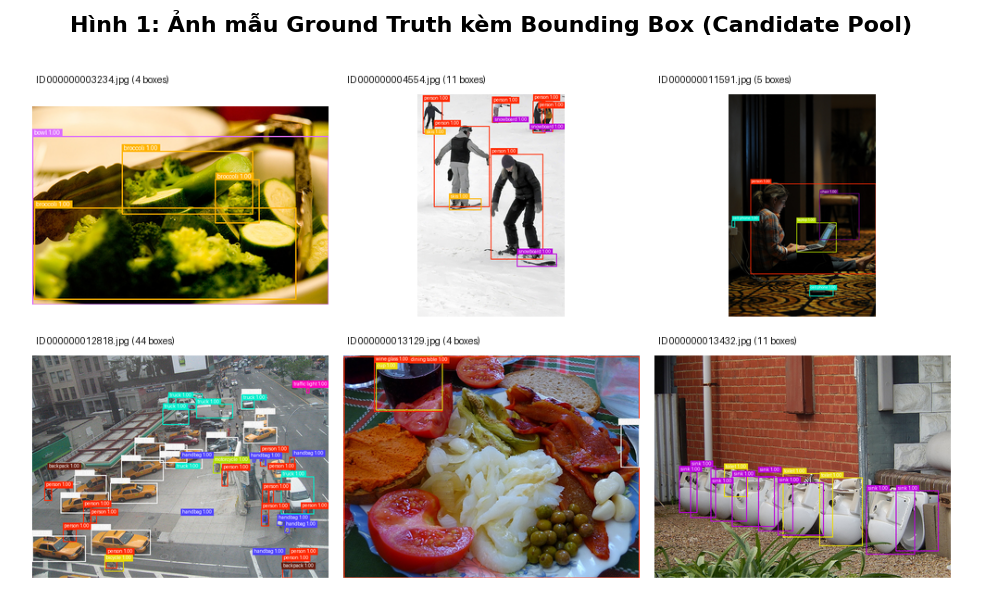

In [14]:
sample_pool_frames = [f for f in pool_dets if len(f) >= 3][:6]
sample_cells = graphics.compose([
    graphics.cell(frame, width=320, height=240, title=f"ID {frame.source_id} ({len(frame)} boxes)")
    for frame in sample_pool_frames
])
graphics.grid(sample_cells, rows=2, cols=3, title="Ảnh mẫu Ground Truth kèm Bounding Box (Candidate Pool)", save_path=REPORT_DIR / "fig_01_sample_ground_truth.png", dpi=300)

In [15]:
dup_report = mining.find_duplicates(pool_dets, exact=True, method="phash", threshold=DEDUP_THRESHOLD)
clean_pool = mining.deduplicate(pool_dets, keep="best", threshold=DEDUP_THRESHOLD)

dedup_summary = {
    "pool_before": len(pool_dets),
    "duplicate_groups": len(dup_report.groups),
    "removed_duplicates": len(pool_dets) - len(clean_pool),
    "pool_after_dedup": len(clean_pool),
}
files.save(LOG_DIR / "03a_deduplication.json", dedup_summary, overwrite=True, verbose=False)
utils.tabulate(dedup_summary, orient="horizontal", title="Kiểm tra & Khử ảnh trùng lặp (MD5 + pHash)")

Bảng 5a: Kiểm tra & Khử ảnh trùng lặp (MD5 + pHash)                
 ──────────────────────────────────────────────────────────────────────────────── 
   pool_before     duplicate_groups     removed_duplicates     pool_after_dedup   
 ──────────────────────────────────────────────────────────────────────────────── 
           400                    0                      0                  400   
 ────────────────────────────────────────────────────────────────────────────────

In [16]:
pool_stats = mining.stats(clean_pool, quality=True, cooccurrence=False)
pool_summary = {
    "images": pool_stats.images,
    "total_boxes": pool_stats.boxes,
    "positive_images": pool_stats.images - pool_stats.empty_images,
    "background_images": pool_stats.empty_images,
    "classes_present": pool_stats.present_classes or len(pool_stats.boxes_per_class),
    "mean_boxes_per_image": round(pool_stats.boxes / max(1, pool_stats.images), 2),
    "imbalance_ratio": round(float(pool_stats.imbalance_ratio), 2),
}
files.save(LOG_DIR / "03b_ground_truth_analysis.json", pool_summary, overwrite=True, verbose=False)
utils.tabulate(pool_summary, orient="horizontal", title="Tổng quan Ground Truth sau khử trùng lặp")


Bảng 5b: Tổng quan Ground Truth sau khử trùng lặp                                           
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   images     total_boxes     positive_images     background_images     classes_present     mean_boxes_per_image     imbalance_ratio   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      400            3071                 398                     2                  79                     7.68               215.0   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [17]:
sorted_classes = sorted(pool_stats.boxes_per_class.items(), key=lambda kv: kv[1], reverse=True)
utils.tabulate(
    [{"rank": i + 1, "class": name, "boxes": cnt} for i, (name, cnt) in enumerate(sorted_classes[:15])],
    title="Top 15 lớp phổ biến nhất trong Candidate Pool",
)


Bảng 6a: Top 15 lớp phổ biến nhất   
         trong Candidate Pool         
 ──────────────────────────────────── 
   rank     class             boxes   
 ──────────────────────────────────── 
      1     person              944   
 ──────────────────────────────────── 
      2     car                 167   
 ──────────────────────────────────── 
      3     chair               145   
 ──────────────────────────────────── 
      4     bottle               77   
 ──────────────────────────────────── 
      5     book                 69   
 ──────────────────────────────────── 
      6     bowl                 61   
 ──────────────────────────────────── 
      7     cup                  60   
 ──────────────────────────────────── 
      8     umbrella             53   
 ──────────────────────────────────── 
      9     bicycle              52   
 ──────────────────────────────────── 
     10     handbag              52   
 ──────────────────────────────────── 
     11     dining table         50   
 ──────────────────────────────────── 
     12     sheep                50   
 ──────────────────────────────────── 
     13     traffic light        47   
 ──────────────────────────────────── 
     14     broccoli             46   
 ──────────────────────────────────── 
     15     bird                 38   
 ────────────────────────────────────

In [18]:
utils.tabulate(
    [{"rank": len(sorted_classes) - i, "class": name, "boxes": cnt} for i, (name, cnt) in enumerate(reversed(sorted_classes[-15:]))],
    title="Bottom 15 lớp hiếm nhất (Long-Tail) trong Candidate Pool",
)

Bảng 6b: Bottom 15 lớp hiếm nhất   
   (Long-Tail) trong Candidate Pool   
 ──────────────────────────────────── 
   rank     class             boxes   
 ──────────────────────────────────── 
     79     bear                  1   
 ──────────────────────────────────── 
     78     parking meter         4   
 ──────────────────────────────────── 
     77     hair drier            4   
 ──────────────────────────────────── 
     76     refrigerator          5   
 ──────────────────────────────────── 
     75     hot dog               5   
 ──────────────────────────────────── 
     74     zebra                 6   
 ──────────────────────────────────── 
     73     mouse                 6   
 ──────────────────────────────────── 
     72     keyboard              6   
 ──────────────────────────────────── 
     71     frisbee               6   
 ──────────────────────────────────── 
     70     stop sign             7   
 ──────────────────────────────────── 
     69     oven                  7   
 ──────────────────────────────────── 
     68     microwave             7   
 ──────────────────────────────────── 
     67     fire hydrant          7   
 ──────────────────────────────────── 
     66     cat                   8   
 ──────────────────────────────────── 
     65     giraffe               9   
 ────────────────────────────────────

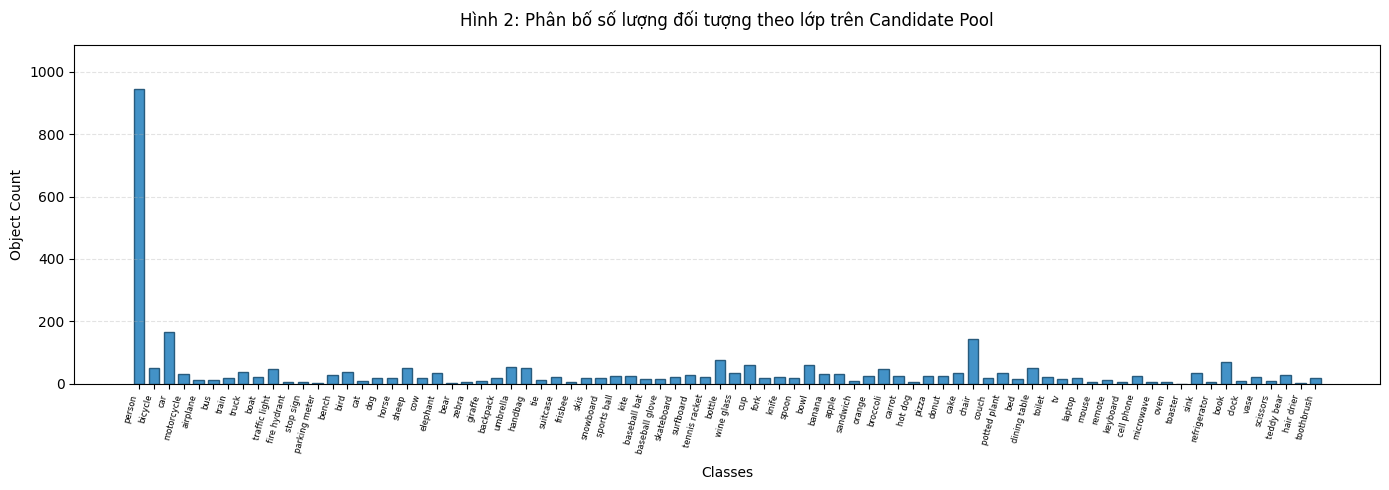

In [19]:
graphics.dataset_stats(
    POOL_YOLO_DIR,
    format="yolo",
    figsize=(14, 5),
    title="Phân bố số lượng đối tượng theo lớp trên Candidate Pool",
    save_path=REPORT_DIR / "fig_02_pool_class_distribution.png",
    dpi=300,
)

## 4. Khai phá dữ liệu — Chấm điểm, Phân cụm & 11 Chiến lược chọn mẫu (`klygo.mining`)

In [20]:
density_scores = mining.score(clean_pool, weights={"boxes": 0.8, "coverage": 0.2})
weighted_scores = mining.score(clean_pool, weights={"quality": 0.3, "rarity": 0.4, "coverage": 0.2, "boxes": 0.1})

In [21]:
cluster_div = mining.cluster(clean_pool, clusters=min(TRAIN_BUDGET, len(clean_pool)), seed=SEED)
cluster_grp = mining.cluster(clean_pool, clusters=N_CLUSTERS, seed=SEED)

In [22]:
# 1. Random Sampling
sub_random = mining.select(clean_pool, method="random", limit=TRAIN_BUDGET, seed=SEED)
print(f"random: {len(sub_random)} images")

random: 100 images


In [23]:
# 2. Rare-First
sub_rare_first = mining.select(clean_pool, method="rare_first", limit=TRAIN_BUDGET)
print(f"rare_first: {len(sub_rare_first)} images")

rare_first: 100 images


In [24]:
# 3. Density (ưu tiên mật độ box)
sub_density = mining.select(clean_pool, method="weighted", scores=density_scores, limit=TRAIN_BUDGET)
print(f"density: {len(sub_density)} images")

density: 100 images


In [25]:
# 4. Weighted Multi-Criteria (quality + rarity + coverage + boxes)
sub_weighted = mining.select(clean_pool, method="weighted", scores=weighted_scores, limit=TRAIN_BUDGET)
print(f"weighted: {len(sub_weighted)} images")

weighted: 100 images


In [26]:
# 5. Visual Quality
sub_quality = mining.select(clean_pool, method="quality", threshold=0.0, limit=TRAIN_BUDGET)
print(f"quality: {len(sub_quality)} images")

quality: 100 images


In [27]:
# 6. Box Constraints (min_boxes + min_area_ratio)
sub_boxes = mining.select(clean_pool, method="boxes", min_boxes=2, min_area_ratio=0.002, limit=TRAIN_BUDGET)
print(f"boxes: {len(sub_boxes)} images")

boxes: 100 images


In [28]:
# 7. Class Coverage (tối đa hóa độ phủ lớp, tự động bù đủ TRAIN_BUDGET)
sub_coverage = mining.select(clean_pool, method="coverage", limit=TRAIN_BUDGET)
print(f"coverage: {len(sub_coverage)} images")

coverage: 100 images


In [29]:
# 8. Per-Class Quota
sub_quota = mining.select(clean_pool, method="quota", per_class=10, limit=TRAIN_BUDGET)
print(f"quota: {len(sub_quota)} images")

quota: 100 images


In [30]:
# 9. Diversity K-Means++ (550 cụm x 1 đại diện)
sub_diversity = mining.select(clean_pool, method="diversity", cluster_result=cluster_div, per_cluster=1, limit=TRAIN_BUDGET, seed=SEED)
print(f"diversity: {len(sub_diversity)} images")

diversity: 100 images


In [31]:
# 10. Clustering K-Means++ (25 cụm x quota, có cơ chế tự bù)
per_cluster_quota = max(1, (TRAIN_BUDGET + N_CLUSTERS - 1) // N_CLUSTERS)
sub_clustering = mining.select(clean_pool, method="diversity", cluster_result=cluster_grp, per_cluster=per_cluster_quota, limit=TRAIN_BUDGET, seed=SEED)
print(f"clustering: {len(sub_clustering)} images")

clustering: 100 images


In [32]:
# 11. Class Balancing (mining.balance)
balanced_pool = mining.balance(clean_pool, target="median", count_by="images", seed=SEED)
sub_balance = mining.select(balanced_pool, method="random", limit=TRAIN_BUDGET, seed=SEED)
print(f"balance: {len(sub_balance)} images (from {len(balanced_pool)} balanced pool)")

balance: 100 images (from 313 balanced pool)


## 5. Thống kê, Trực quan hóa & Xuất 11 bộ dữ liệu YOLO

In [33]:
selections = {
    "random": sub_random,
    "rare_first": sub_rare_first,
    "density": sub_density,
    "weighted": sub_weighted,
    "quality": sub_quality,
    "boxes": sub_boxes,
    "coverage": sub_coverage,
    "quota": sub_quota,
    "diversity": sub_diversity,
    "clustering": sub_clustering,
    "balance": sub_balance,
}
files.save(LOG_DIR / "04_mining_selections.json", {k: [f.source_id for f in v] for k, v in selections.items()}, overwrite=True, verbose=False)

In [34]:
mining_rows = reports.mining_breakdown(selections)
for row in mining_rows:
    delta = mining.compare(clean_pool, selections[row["strategy"]], quality=False)
    row["class_coverage"] = delta.after.present_classes or len(delta.after.boxes_per_class)
    row["imbalance_ratio"] = round(float(delta.after.imbalance_ratio), 2)

files.save(REPORT_DIR / "table_mining_breakdown.csv", mining_rows, overwrite=True, verbose=False)
utils.tabulate(mining_rows, title="Thống kê đặc trưng tập dữ liệu chọn bởi 11 chiến lược Data Mining")


Bảng 7: Thống kê đặc trưng tập dữ liệu chọn bởi 11 chiến lược Data Mining                                                                   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   strategy       images     positive_images     positive_pct     background_images     background_pct     boxes     boxes_per_positive     mean_conf     median_conf     class_coverage     imbalance_ratio   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random            100                 100            100.0                     0                0.0       834                   8.34           1.0             1.0                 63                52.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   rare_first        100                 100            100.0                     0                0.0       535                   5.35           1.0             1.0                 58                17.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   density           100                 100            100.0                     0                0.0      1893                  18.93           1.0             1.0                 70                76.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted          100                 100            100.0                     0                0.0      1502                  15.02           1.0             1.0                 76                52.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   quality           100                  99             99.0                     1                1.0       701                   7.08           1.0             1.0                 70                43.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   boxes             100                 100            100.0                     0                0.0       773                   7.73           1.0             1.0                 70                55.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage          100                 100            100.0                     0                0.0      1697                  16.97           1.0             1.0                 79                71.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   quota             100                 100            100.0                     0                0.0      1309                  13.09           1.0             1.0                 72                66.0   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────

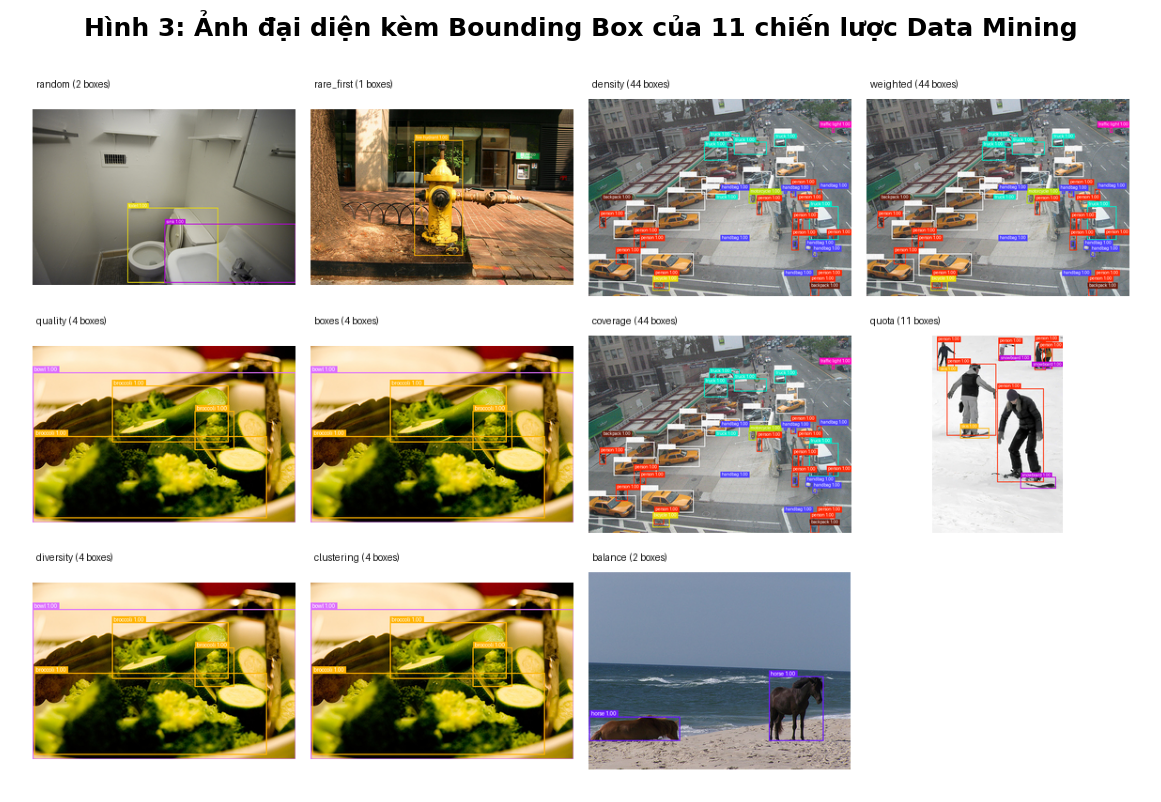

In [35]:
rep_cells = graphics.compose([
    graphics.cell(
        next((f for f in subset if len(f) > 0), subset[0]),
        width=280,
        height=210,
        title=f"{name} ({len(next((f for f in subset if len(f) > 0), subset[0]))} boxes)",
    )
    for name, subset in selections.items()
])
graphics.grid(rep_cells, rows=3, cols=4, title="Ảnh đại diện kèm Bounding Box của 11 chiến lược Data Mining", save_path=REPORT_DIR / "fig_03_mining_representative_samples.png", dpi=300)

In [36]:
dataset_yamls = {}
for strategy, subset in selections.items():
    strat_dir = DATASET_DIR / strategy
    subset.export(str(strat_dir), format="yolo", image=True, overwrite=True)

    yaml_path = strat_dir / "data.yaml"
    data_cfg = config.load(yaml_path, verbose=False)
    data_cfg = config.set(data_cfg, "path", str(strat_dir))
    data_cfg = config.set(data_cfg, "train", "images")
    data_cfg = config.set(data_cfg, "val", str(VAL_YOLO_DIR / "images"))
    files.save(yaml_path, data_cfg.to_dict(), overwrite=True, verbose=False)
    dataset_yamls[strategy] = str(yaml_path)

In [37]:
partition_rows = reports.partition_summary({"val2017": VAL_YOLO_DIR, **{k: DATASET_DIR / k for k in selections}}, format="yolo")
files.save(LOG_DIR / "05_partition_summary.json", partition_rows, overwrite=True, verbose=False)
utils.tabulate(partition_rows, title="Kiểm tra toàn vẹn & số lượng ảnh/box 11 bộ YOLO đã xuất")

Bảng 8: Kiểm tra toàn vẹn & số lượng ảnh/box 11 bộ YOLO đã xuất                 
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   split          images     positive_images     background_images     gt_boxes     ratio_pct   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   val2017           100                  99                     1          709          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   random            100                 100                     0          834          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   rare_first        100                 100                     0          535          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   density           100                 100                     0         1893          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted          100                 100                     0         1502          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   quality           100                  99                     1          701          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   boxes             100                 100                     0          773          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage          100                 100                     0         1697          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   quota             100                 100                     0         1309          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   diversity         100                  99                     1          808          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   clustering        100                 100                     0          719          8.33   
 ────────────────────────────────────────────────────────────────────────────────────────────── 
   balance           100                 100                     0          718          8.33   
 ──────────────────────────────────────────────────────────────────────────────────────────────

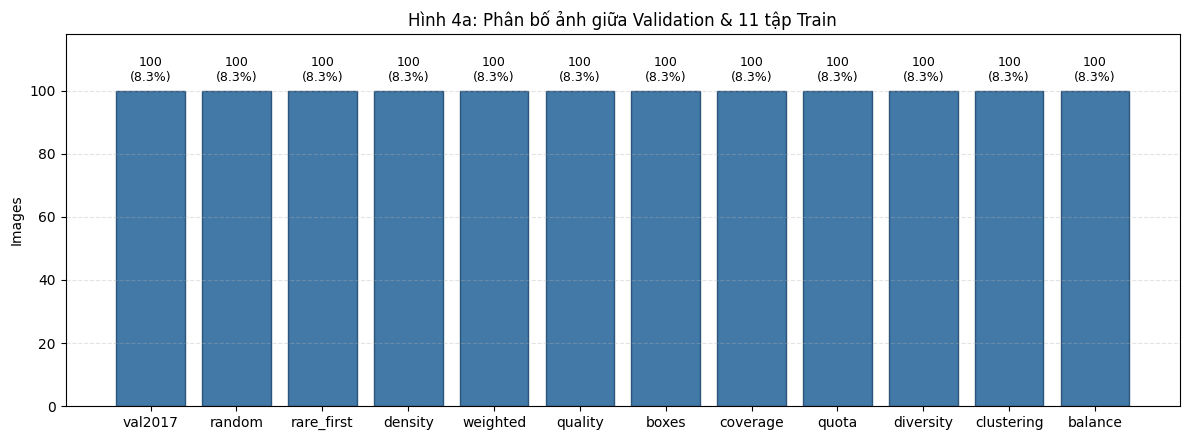

In [38]:
fig_part = graphics.partitions(
    partition_rows,
    figsize=(12, 4.5),
    title="Phân bố ảnh giữa Validation & 11 tập Train",
    save_path=REPORT_DIR / "fig_04a_partitions.png",
    show=False,
    return_figure=True,
)

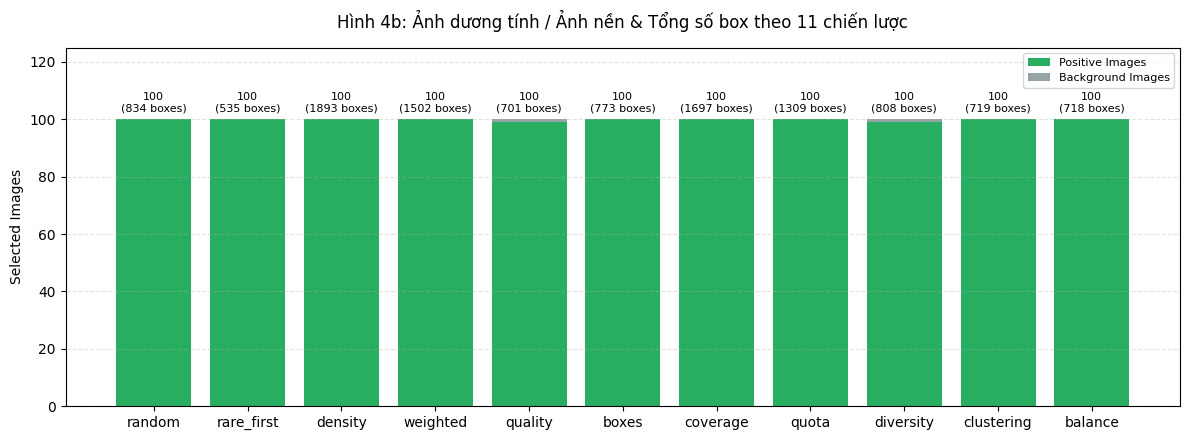

In [39]:
fig_mining = graphics.mining(
    mining_rows,
    kind="counts",
    figsize=(12, 4.5),
    title="Ảnh dương tính / Ảnh nền & Tổng số box theo 11 chiến lược",
    save_path=REPORT_DIR / "fig_04b_mining_counts.png",
    show=False,
    return_figure=True,
)

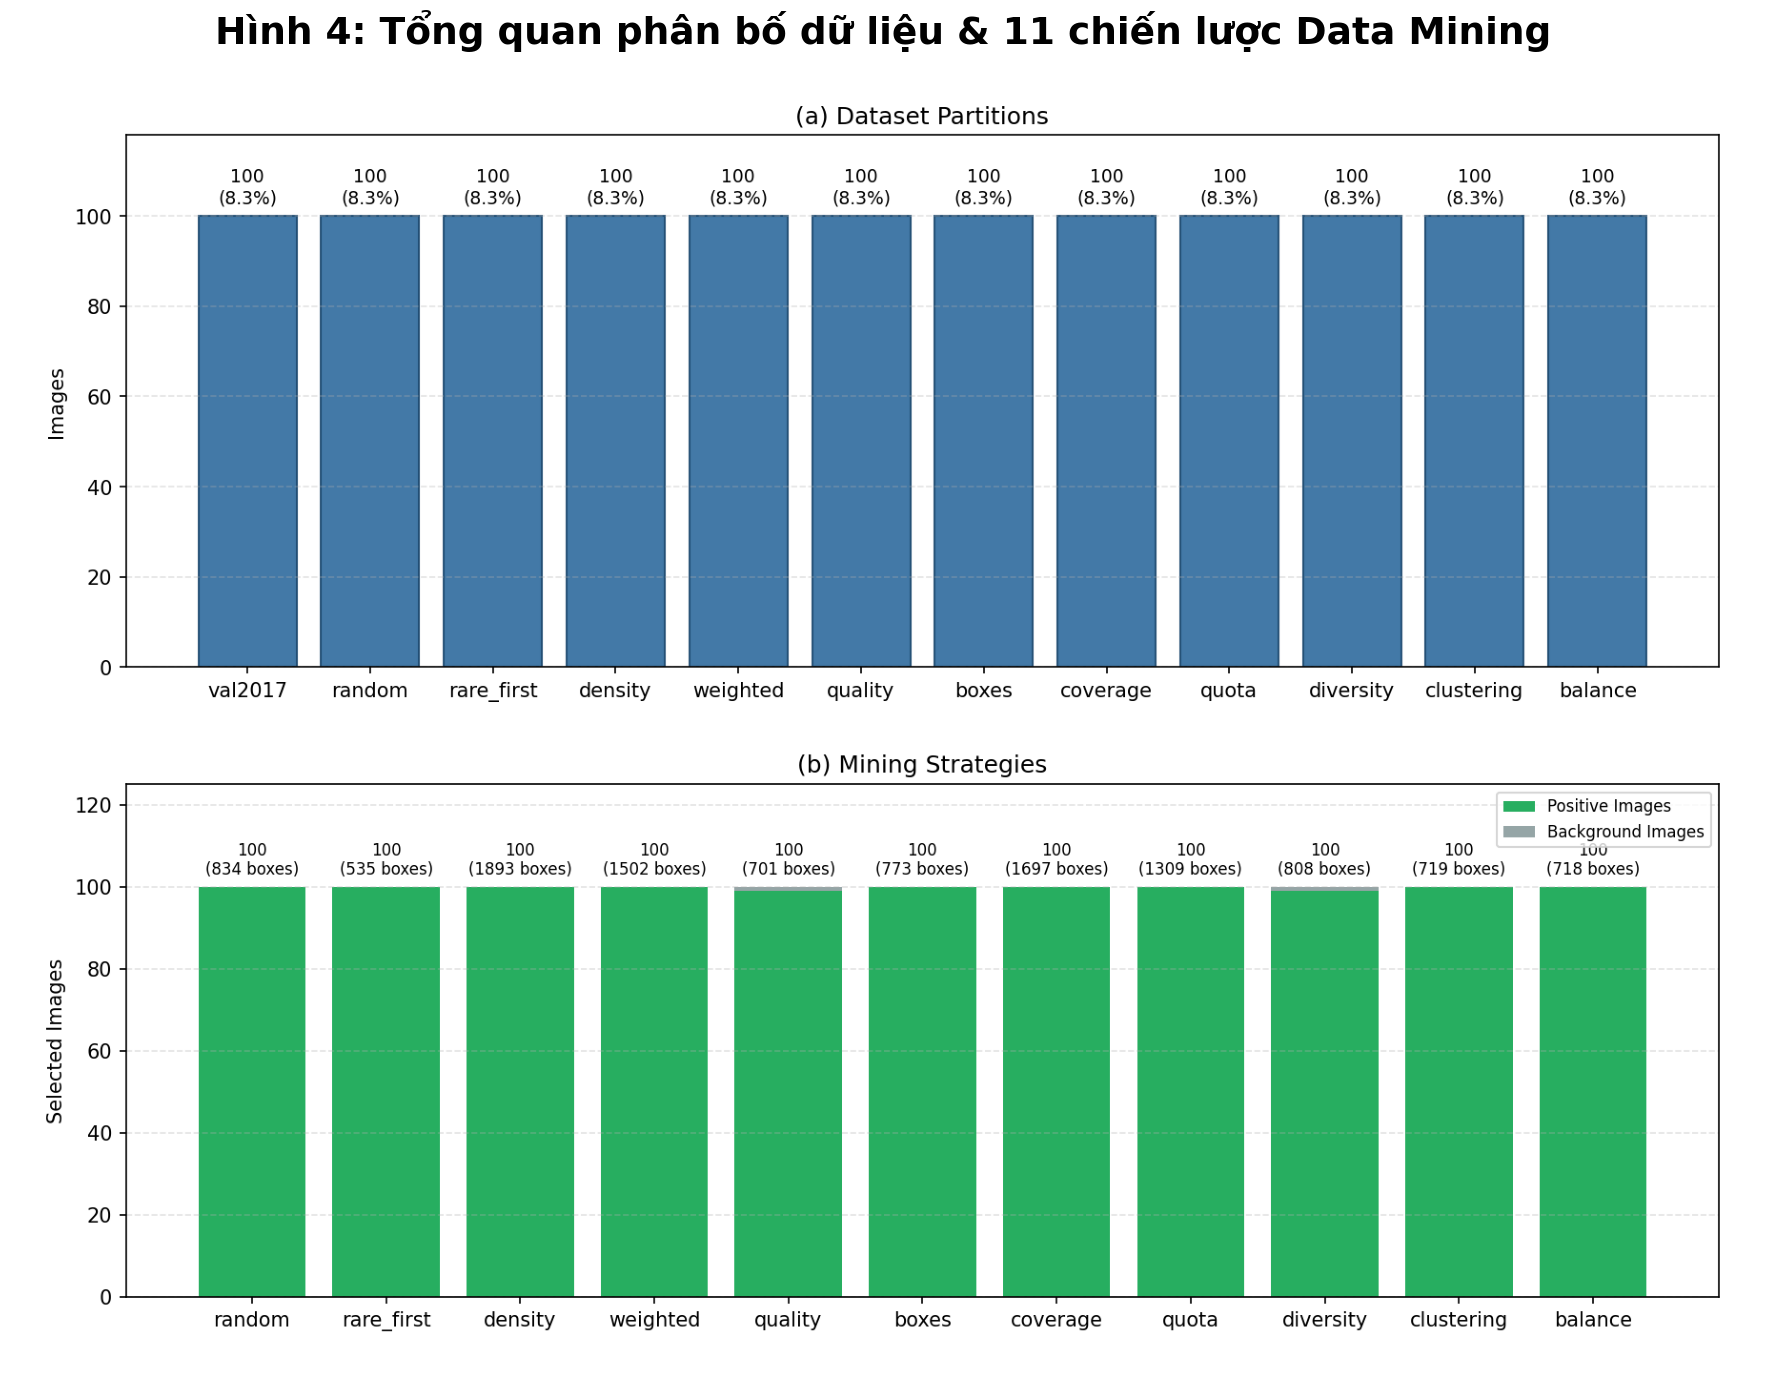

In [40]:
overview_cells = graphics.compose([
    graphics.cell(fig_part, title="(a) Dataset Partitions"),
    graphics.cell(fig_mining, title="(b) Mining Strategies"),
])
graphics.grid(overview_cells, rows=2, cols=1, title="Tổng quan phân bố dữ liệu & 11 chiến lược Data Mining", save_path=REPORT_DIR / "fig_04_dataset_and_mining_overview.png", dpi=300)

## 6. Huấn luyện 11 Student YOLO11n & Đánh giá trên `val2017`

In [41]:
run_dirs, best_checkpoints = {}, {}

if RUN_TRAINING:
    for strategy in selections:
        print(f"\n{'=' * 20} TRAIN: {strategy} {'=' * 20}")
        detector = models.load(MODEL_NAME)
        run_name = f"yolo11n_{strategy}"
        detector.model.train(
            data=dataset_yamls[strategy],
            project=str(RUNS_DIR),
            name=run_name,
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            workers=WORKERS,
            device=DEVICE,
            seed=SEED,
            deterministic=True,
            patience=EPOCHS,
            exist_ok=True,
        )
        run_dir = RUNS_DIR / run_name
        run_dirs[strategy] = [str(run_dir)]
        ckpt_src = run_dir / "weights" / "best.pt" if files.is_file(run_dir / "weights" / "best.pt") else run_dir / "weights" / "last.pt"
        ckpt_dst = CHECKPOINT_DIR / f"{strategy}_best.pt"
        files.copy(ckpt_src, ckpt_dst, overwrite=True)
        best_checkpoints[strategy] = str(ckpt_dst)
        del detector
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


==================== TRAIN: random ====================
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/coco_mining_project/artifacts/datasets/random/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mo

In [42]:
if run_dirs:
    c = reports.load(next(iter(run_dirs.values()))[0], format="yolo")["config"]
    hyper_table = {
        "Mô hình": c.get("model"),
        "Kích thước ảnh / Batch / Epoch": f"imgsz={c.get('imgsz')}; batch={c.get('batch')}; epochs={c.get('epochs')} (patience={c.get('patience')})",
        "Optimizer": f"{c.get('optimizer')} (lr0={c.get('lr0')}, momentum={c.get('momentum')})",
        "Weight decay & Warmup": f"weight_decay={c.get('weight_decay')}; warmup_epochs={c.get('warmup_epochs')}",
        "Trọng số Loss": f"box={c.get('box')}, cls={c.get('cls')}, dfl={c.get('dfl')}",
        "Augmentation": f"mosaic={c.get('mosaic')} (close_mosaic={c.get('close_mosaic')}), fliplr={c.get('fliplr')}, scale={c.get('scale')}, AMP={c.get('amp')}",
        "Kiểm soát ngẫu nhiên": f"deterministic={c.get('deterministic')}, seed={c.get('seed')}",
    }
    utils.tabulate(hyper_table, title="Cấu hình siêu tham số huấn luyện từ args.yaml", key_header="Tham số", value_header="Giá trị")

Bảng 9: Cấu hình siêu tham số huấn luyện từ args.yaml                         
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Tham số                            Giá trị                                                         
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Mô hình                            yolo11n.pt                                                      
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Kích thước ảnh / Batch / Epoch     imgsz=640; batch=16; epochs=2 (patience=2)                      
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Optimizer                          auto (lr0=0.01, momentum=0.937)                                 
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Weight decay & Warmup              weight_decay=0.0005; warmup_epochs=3.0                          
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Trọng số Loss                      box=7.5, cls=0.5, dfl=1.5                                       
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Augmentation                       mosaic=1.0 (close_mosaic=10), fliplr=0.5, scale=0.5, AMP=True   
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
   Kiểm soát ngẫu nhiên               deterministic=True, seed=42                                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────

In [43]:
training_records = []
val_results = {}

for strategy, ckpt_path in best_checkpoints.items():
    detector = models.load(ckpt_path)
    yolo_val = detector.model.val(
        data=dataset_yamls[strategy],
        split="val",
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        verbose=False,
    )

    mp = float(yolo_val.box.mp)
    mr = float(yolo_val.box.mr)
    f1 = float(metrics.f1_score(mp, mr))
    map50 = float(yolo_val.box.map50)
    map75 = float(yolo_val.box.map75)
    map50_95 = float(yolo_val.box.map)

    record = {
        "strategy": strategy,
        "train_images": len(selections[strategy]),
        "precision": round(mp, 4),
        "recall": round(mr, 4),
        "f1": round(f1, 4),
        "mAP50": round(map50, 4),
        "mAP75": round(map75, 4),
        "mAP50-95": round(map50_95, 4),
    }
    training_records.append(record)
    val_results[strategy] = yolo_val
    files.save(LOG_DIR / f"eval_{strategy}.json", record, overwrite=True, verbose=False)
    del detector
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,612,117 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2892.2±657.5 MB/s, size: 174.4 KB)
val: Scanning /content/coco_mining_project/artifacts/datasets/val_yolo/labels... 100 images, 1 backgrounds, 21 corrupt: 100% ━━━━━━━━━━━━ 100/100 2.0Kit/s 0.0s
val: /content/coco_mining_project/artifacts/datasets/val_yolo/images/000000006213.jpg: ignoring corrupt image/label: Label class 71 exceeds dataset class count 63. Possible class labels are 0-62
val: /content/coco_mining_project/artifacts/datasets/val_yolo/images/000000022371.jpg: ignoring corrupt image/label: Label class 73 exceeds dataset class count 63. Possible class labels are 0-62
val: /content/coco_mining_project/artifacts/datasets/val_yolo/images/000000022623.jpg: ignoring corrupt image/label: Label class 67 exceeds dataset class count 63. Possible class labels are 0-62
val

## 7. Bảng tổng hợp kết quả & Phân tích chi tiết (`klygo.reports` + `utils.tabulate`)

In [44]:
if run_dirs:
    agg = reports.aggregate_runs(run_dirs, format="yolo", best="auto")
    files.save(REPORT_DIR / "table_training_logs.csv", agg["table"], overwrite=True, verbose=False)
    utils.tabulate(agg["table"], title="Tổng hợp nhật ký huấn luyện từ results.csv")

Bảng 10: Tổng hợp nhật ký huấn luyện từ results.csv                                                                                           
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   strategy       seeds     precision_mean     precision_std     recall_mean     recall_std     f1_mean     f1_std     mAP50_mean     mAP50_std     mAP50-95_mean     mAP50-95_std     time_mean_s     time_std_s     best_epoch_mean   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random             1             0.4097               0.0          0.0379            0.0      0.0694        0.0         0.0507           0.0            0.0348              0.0           14.14            0.0                 2.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   rare_first         1              0.517               0.0          0.0144            0.0      0.0281        0.0         0.0193           0.0            0.0126              0.0            8.14            0.0                 1.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   density            1             0.3553               0.0          0.0418            0.0      0.0748        0.0          0.055           0.0            0.0379              0.0            7.56            0.0                 1.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted           1             0.3912               0.0          0.1645            0.0      0.2316        0.0         0.1857           0.0            0.1411              0.0            8.59            0.0                 2.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   quality            1             0.3294               0.0           0.046            0.0      0.0807        0.0         0.0456           0.0            0.0305              0.0            7.14            0.0                 1.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   boxes              1              0.379               0.0          0.0804            0.0      0.1327        0.0         0.1002           0.0            0.0714              0.0            8.69            0.0                 2.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage           1             0.6835               0.0          0.4676            0.0      0.5553        0.0         0.5399           0.0            0.4063              0.0            8.27            0.0                 1.0   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [45]:
leaderboard_rows = []
if training_records:
    base_map = next((r["mAP50-95"] for r in training_records if r["strategy"] == "random"), 0.0)
    for rank, row in enumerate(sorted(training_records, key=lambda r: r["mAP50-95"], reverse=True), start=1):
        delta = round(row["mAP50-95"] - base_map, 4)
        delta_pct = round((100.0 * delta / base_map) if base_map else 0.0, 2)
        leaderboard_rows.append({"rank": rank, **row, "delta_vs_random": delta, "delta_pct": delta_pct})
    files.save(REPORT_DIR / "table_leaderboard.csv", leaderboard_rows, overwrite=True, verbose=False)
    utils.tabulate(leaderboard_rows, title="Bảng xếp hạng 11 chiến lược Data Mining trên COCO val2017")

Bảng 11: Bảng xếp hạng 11 chiến lược Data Mining trên COCO val2017                                         
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   rank     strategy       train_images     precision     recall         f1      mAP50      mAP75     mAP50-95     delta_vs_random     delta_pct   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      1     coverage                100        0.6761     0.4597     0.5473      0.533     0.4421       0.4062               0.372       1087.72   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      2     weighted                100         0.376      0.165     0.2293     0.1846     0.1615       0.1398              0.1056        308.77   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      3     balance                 100        0.3411     0.0944     0.1479      0.112     0.0949       0.0817              0.0475        138.89   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      4     boxes                   100        0.3319     0.1006     0.1543     0.1002     0.0818       0.0734              0.0392        114.62   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      5     clustering              100        0.3487     0.0724     0.1199     0.0885     0.0726       0.0649              0.0307         89.77   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      6     density                 100        0.4169     0.0384     0.0703     0.0572     0.0407       0.0385              0.0043         12.57   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      7     random                  100        0.4093     0.0382     0.0699     0.0511     0.0347       0.0342                 0.0           0.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      8     quota                   100        0.3007     0.0352      0.063     0.0455     0.0349       0.0313             -0.0029         -8.48   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
      9     quality                 100        0.4055     0.0357     0.0657     0.0451     0.0315       0.0299             -0.0043        -12.57   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
     10     diversity               100        0.3179     0.0254     0.0471     0.0353     0.0244       0.0232              -0.011        -32.16   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
     11     rare_first              100        0.5171     0.0143     0.0279     0.0195     0.0132       0.0127             -0.0215        -62.87   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [46]:
if leaderboard_rows:
    best_strategy = leaderboard_rows[0]["strategy"]
    best_val = val_results[best_strategy]
    if hasattr(best_val.box, "all_ap") and best_val.box.all_ap is not None and len(best_val.box.all_ap):
        ious = np.linspace(0.5, 0.95, 10)
        iou_maps = best_val.box.all_ap.mean(axis=0)
        map50 = float(iou_maps[0]) if len(iou_maps) else float(best_val.box.map50)
        iou_rows = []
        for iou, m in zip(ious, iou_maps):
            iou_f = round(float(iou), 2)
            m_f = round(float(m), 4)
            delta = round(m_f - map50, 4)
            retention = f"{round(100.0 * m_f / max(1e-6, map50), 1)}%"
            if iou_f <= 0.60:
                tier = "Cơ bản (Loose)"
            elif iou_f <= 0.75:
                tier = "Tiêu chuẩn (COCO)"
            else:
                tier = "Khắt khe (Strict)"
            iou_rows.append({
                "IoU": f"{iou_f:.2f}",
                "mAP": m_f,
                "delta_vs_50": delta,
                "retention": retention,
                "tier": tier,
            })
    else:
        map50 = float(best_val.box.map50)
        map75 = float(best_val.box.map75)
        map_all = float(best_val.box.map)
        iou_rows = [
            {"IoU": "0.50", "mAP": round(map50, 4), "delta_vs_50": 0.0, "retention": "100.0%", "tier": "Cơ bản (Loose)"},
            {"IoU": "0.75", "mAP": round(map75, 4), "delta_vs_50": round(map75 - map50, 4), "retention": f"{round(100.0 * map75 / max(1e-6, map50), 1)}%", "tier": "Tiêu chuẩn (COCO)"},
            {"IoU": "0.50:0.95", "mAP": round(map_all, 4), "delta_vs_50": round(map_all - map50, 4), "retention": f"{round(100.0 * map_all / max(1e-6, map50), 1)}%", "tier": "Tổng hợp (COCO)"},
        ]
    files.save(REPORT_DIR / "table_iou_breakdown.csv", iou_rows, overwrite=True, verbose=False)
    utils.tabulate(iou_rows, title=f"Phân rã mAP theo 10 ngưỡng IoU — {best_strategy}")

Bảng 12a: Phân rã mAP theo 10 ngưỡng IoU — coverage           
 ─────────────────────────────────────────────────────────────────────── 
   IoU         mAP     delta_vs_50     retention     tier                
 ─────────────────────────────────────────────────────────────────────── 
   0.50      0.533             0.0     100.0%        Cơ bản (Loose)      
 ─────────────────────────────────────────────────────────────────────── 
   0.55     0.5187         -0.0143     97.3%         Cơ bản (Loose)      
 ─────────────────────────────────────────────────────────────────────── 
   0.60     0.5019         -0.0311     94.2%         Cơ bản (Loose)      
 ─────────────────────────────────────────────────────────────────────── 
   0.65     0.4906         -0.0424     92.0%         Tiêu chuẩn (COCO)   
 ─────────────────────────────────────────────────────────────────────── 
   0.70      0.475          -0.058     89.1%         Tiêu chuẩn (COCO)   
 ─────────────────────────────────────────────────────────────────────── 
   0.75     0.4421         -0.0909     82.9%         Tiêu chuẩn (COCO)   
 ─────────────────────────────────────────────────────────────────────── 
   0.80      0.395          -0.138     74.1%         Khắt khe (Strict)   
 ─────────────────────────────────────────────────────────────────────── 
   0.85     0.3271         -0.2059     61.4%         Khắt khe (Strict)   
 ─────────────────────────────────────────────────────────────────────── 
   0.90     0.2339         -0.2991     43.9%         Khắt khe (Strict)   
 ─────────────────────────────────────────────────────────────────────── 
   0.95     0.1443         -0.3887     27.1%         Khắt khe (Strict)   
 ───────────────────────────────────────────────────────────────────────

In [47]:
per_class = []
if leaderboard_rows:
    best_strategy = leaderboard_rows[0]["strategy"]
    best_val = val_results[best_strategy]
    mean_ap = float(best_val.box.map) if hasattr(best_val.box, "map") else 0.0
    has_all_ap = hasattr(best_val.box, "all_ap") and best_val.box.all_ap is not None and len(best_val.box.all_ap)

    if hasattr(best_val.box, "ap_class_index") and best_val.box.ap_class_index is not None:
        for idx, cls_id in enumerate(best_val.box.ap_class_index):
            cls_name = best_val.names.get(cls_id, str(cls_id)) if hasattr(best_val, "names") else str(cls_id)
            ap_val = float(best_val.box.maps[idx]) if idx < len(best_val.box.maps) else 0.0
            ap50_val = float(best_val.box.all_ap[idx, 0]) if has_all_ap and idx < len(best_val.box.all_ap) else None
            per_class.append({
                "class": cls_name,
                "class_id": int(cls_id),
                "AP50": round(ap50_val, 4) if ap50_val is not None else "-",
                "AP50-95": round(ap_val, 4),
                "delta_mean": round(ap_val - mean_ap, 4),
            })
        per_class = sorted(per_class, key=lambda x: x["AP50-95"], reverse=True)

    if per_class:
        top10_rows = []
        for rk, c in enumerate(per_class[:10], start=1):
            grade = "Xuất sắc" if c["AP50-95"] >= 0.60 else ("Tốt" if c["AP50-95"] >= 0.40 else "Đạt")
            top10_rows.append({
                "rank": f"#{rk}",
                "class_id": c["class_id"],
                "class": c["class"],
                "AP50": c["AP50"],
                "AP50-95": c["AP50-95"],
                "delta_mean": c["delta_mean"],
                "grade": grade,
            })
        files.save(REPORT_DIR / "table_top10_classes.csv", top10_rows, overwrite=True, verbose=False)
        utils.tabulate(
            top10_rows,
            title=f"Top 10 lớp có AP cao nhất — {best_strategy}",
        )
    else:
        print("Không có lớp nào có đủ mẫu validation để xếp hạng Top 10.")

Bảng 12b: Top 10 lớp có AP cao nhất — coverage                     
 ────────────────────────────────────────────────────────────────────────────────────── 
   rank     class_id     class           AP50     AP50-95     delta_mean     grade      
 ────────────────────────────────────────────────────────────────────────────────────── 
   #1             20     elephant       0.995       0.995         0.5888     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #2             22     zebra          0.995       0.995         0.5888     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #3              5     bus            0.995       0.945         0.5388     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #4             15     cat            0.995      0.8847         0.4785     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #5             21     bear           0.995      0.8128         0.4066     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #6             68     microwave      0.995       0.797         0.3908     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #7             31     snowboard     0.8283       0.795         0.3888     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #8             73     clock            0.0       0.795         0.3888     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #9             16     dog            0.745       0.745         0.3388     Xuất sắc   
 ────────────────────────────────────────────────────────────────────────────────────── 
   #10            75     scissors         0.0      0.7117         0.3055     Xuất sắc   
 ──────────────────────────────────────────────────────────────────────────────────────

In [48]:
if leaderboard_rows and per_class:
    total_cls = len(per_class)
    bottom10 = per_class[-10:]
    bottom10_rows = []
    for offset, c in enumerate(reversed(bottom10), start=1):
        tier = "Cực khó (AP=0)" if c["AP50-95"] == 0.0 else ("Thách thức cao" if c["AP50-95"] < 0.15 else "Cần thêm dữ liệu")
        bottom10_rows.append({
            "rank": f"#{total_cls - offset + 1}",
            "class_id": c["class_id"],
            "class": c["class"],
            "AP50": c["AP50"],
            "AP50-95": c["AP50-95"],
            "deficit_mean": c["delta_mean"],
            "difficulty": tier,
        })
    files.save(REPORT_DIR / "table_bottom10_classes.csv", bottom10_rows, overwrite=True, verbose=False)
    utils.tabulate(
        bottom10_rows,
        title=f"Bottom 10 lớp khó nhất (Cần khai phá thêm) — {best_strategy}",
    )

Bảng 12c: Bottom 10 lớp khó nhất (Cần khai phá thêm) — coverage                  
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   rank     class_id     class            AP50     AP50-95     deficit_mean     difficulty         
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #67            57     couch          0.0205         0.0          -0.4062     Cực khó (AP=0)     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #66            40     wine glass     0.0369      0.0014          -0.4048     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #65            45     bowl           0.5679      0.0041           -0.402     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #64            63     laptop         0.8117      0.0112          -0.3949     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #63            48     sandwich       0.0474       0.013          -0.3931     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #62            53     pizza          0.6111      0.0308          -0.3754     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #61            17     horse          0.0905      0.0372          -0.3689     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #60             7     truck          0.0905      0.0724          -0.3338     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #59            27     tie            0.3799      0.0774          -0.3288     Thách thức cao     
 ───────────────────────────────────────────────────────────────────────────────────────────────── 
   #58             1     bicycle          0.25       0.158          -0.2482     Cần thêm dữ liệu   
 ─────────────────────────────────────────────────────────────────────────────────────────────────

## 8. Biểu đồ hội tụ, So sánh hiệu năng & Phân tích định tính (`klygo.graphics`)

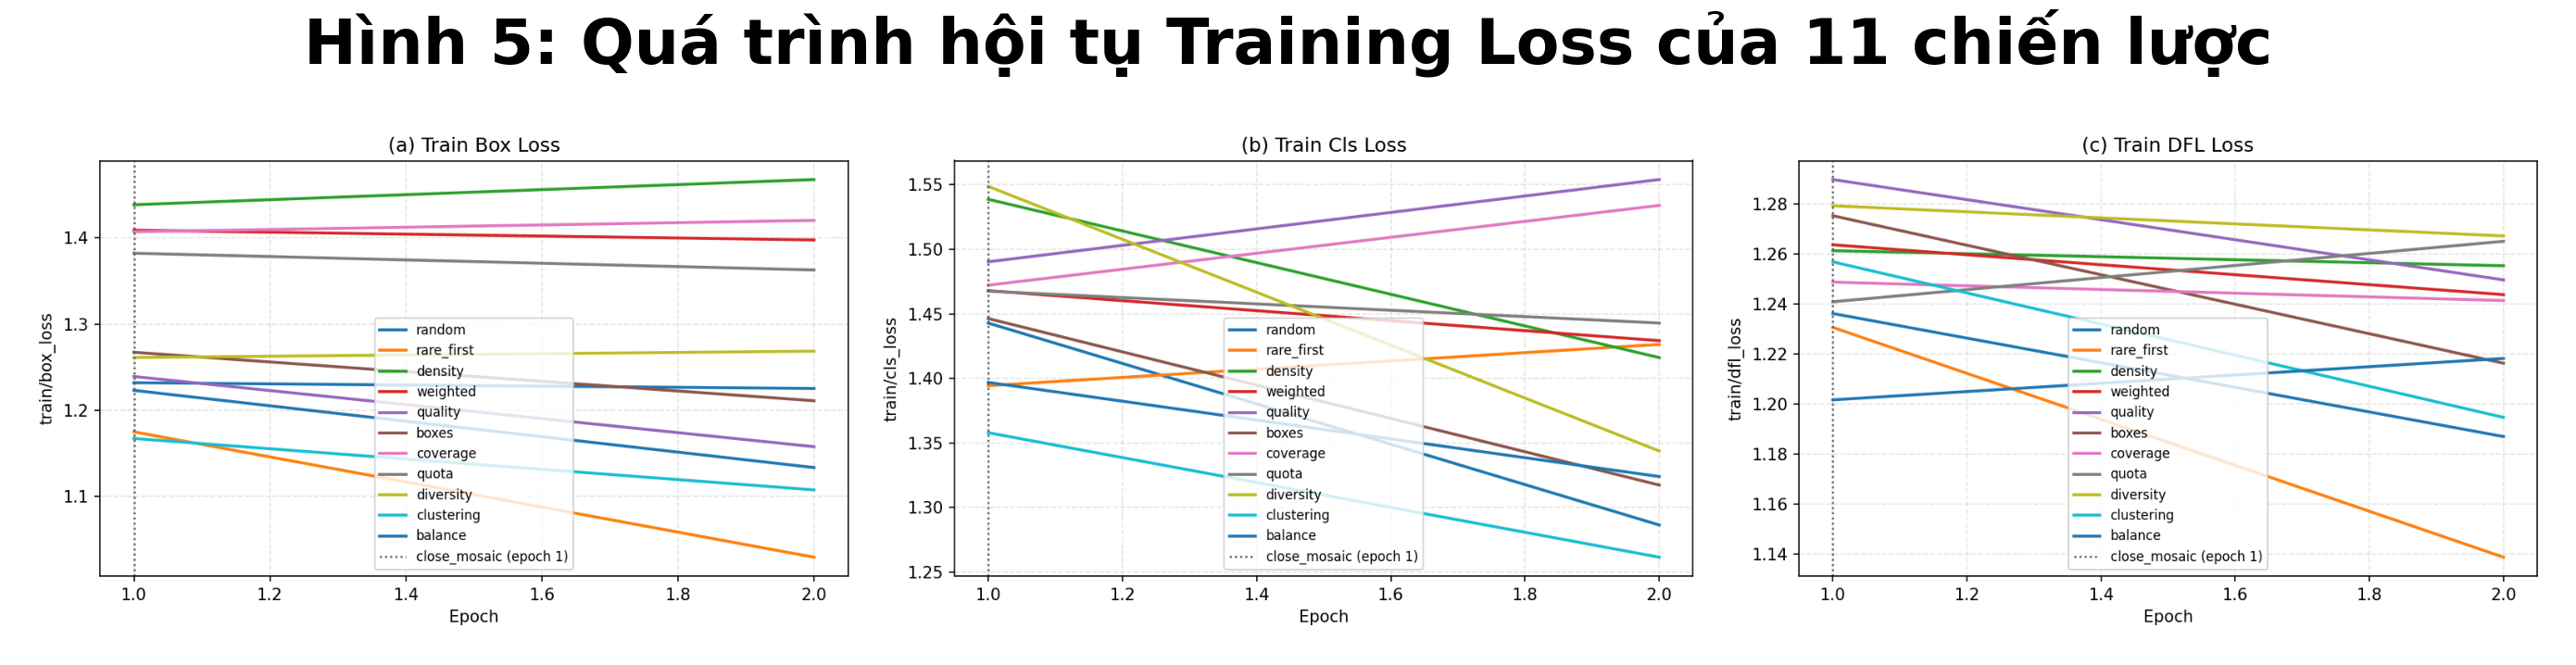

In [49]:
if run_dirs:
    fig_box = graphics.curves(agg, metric="box_loss", split="train", band=False, show=False, return_figure=True)
    fig_cls = graphics.curves(agg, metric="cls_loss", split="train", band=False, show=False, return_figure=True)
    fig_dfl = graphics.curves(agg, metric="dfl_loss", split="train", band=False, show=False, return_figure=True)
    loss_cells = graphics.compose([
        graphics.cell(fig_box, title="(a) Train Box Loss"),
        graphics.cell(fig_cls, title="(b) Train Cls Loss"),
        graphics.cell(fig_dfl, title="(c) Train DFL Loss"),
    ])
    graphics.grid(loss_cells, rows=1, cols=3, title="Quá trình hội tụ Training Loss của 11 chiến lược", save_path=REPORT_DIR / "fig_05_training_loss_curves.png", dpi=300)

In [ ]:
if run_dirs:
    fig_p = graphics.curves(agg, metric="precision", band=False, show=False, return_figure=True)
    fig_r = graphics.curves(agg, metric="recall", band=False, show=False, return_figure=True)
    fig_f1 = graphics.curves(agg, metric="f1", band=False, show=False, return_figure=True)
    prf_cells = graphics.compose([
        graphics.cell(fig_p, title="(a) Validation Precision"),
        graphics.cell(fig_r, title="(b) Validation Recall"),
        graphics.cell(fig_f1, title="(c) Validation F1-Score"),
    ])
    graphics.grid(
        prf_cells,
        rows=1,
        cols=3,
        title="Quá trình tăng trưởng Precision, Recall & F1 qua các Epoch",
        save_path=REPORT_DIR / "fig_06a_validation_prf1_curves.png",
        dpi=300,
    )

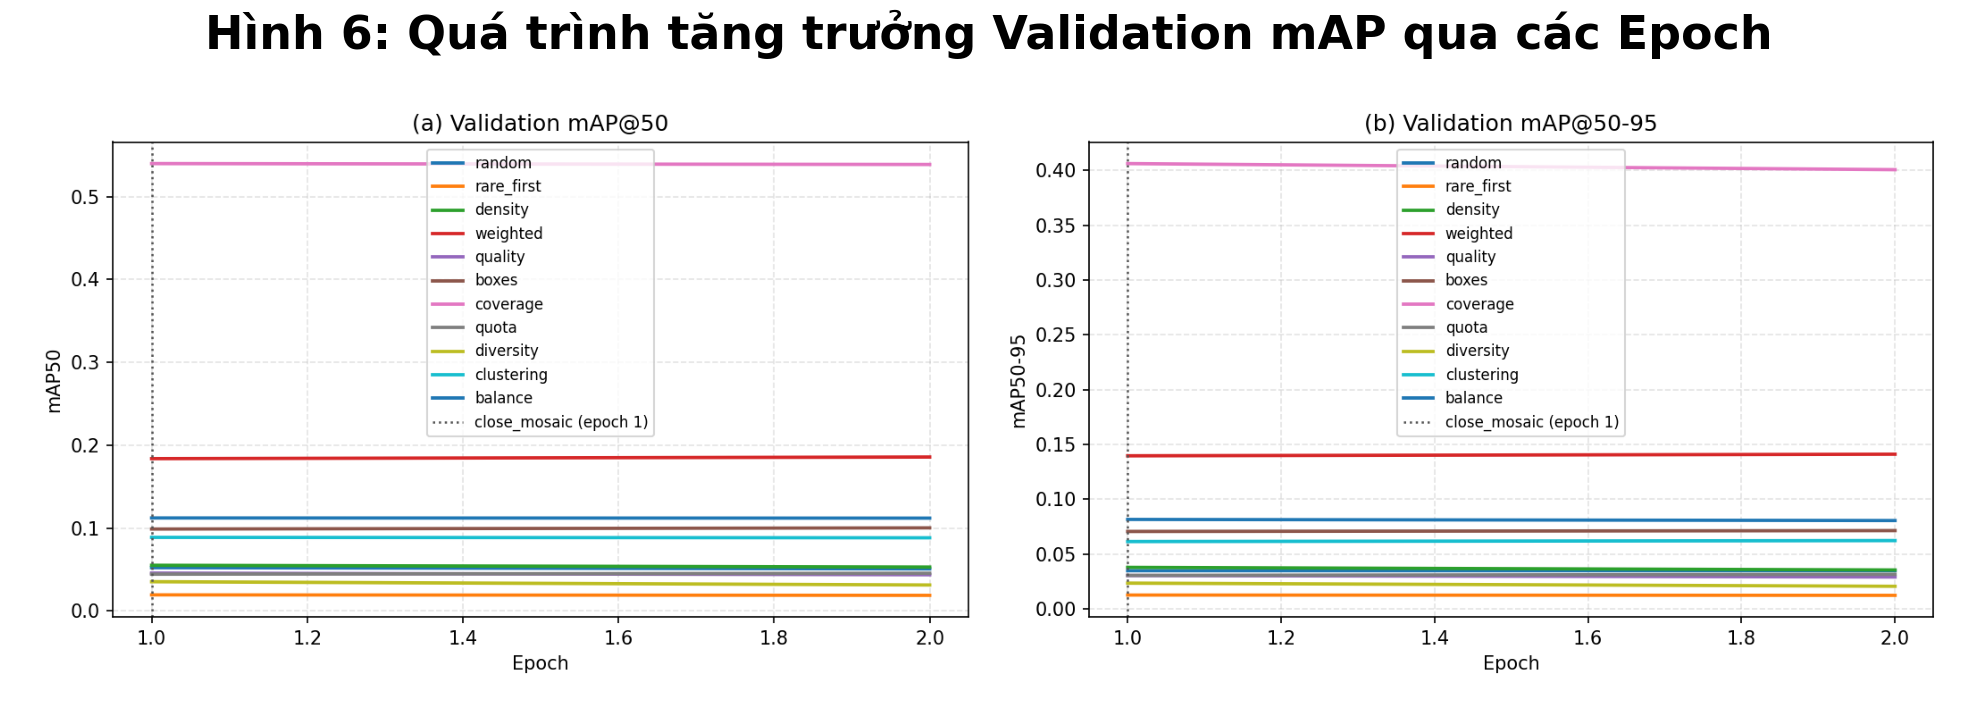

In [50]:
if run_dirs:
    fig_m50 = graphics.curves(agg, metric="mAP50", band=False, show=False, return_figure=True)
    fig_m95 = graphics.curves(agg, metric="mAP50-95", band=False, show=False, return_figure=True)
    map_cells = graphics.compose([
        graphics.cell(fig_m50, title="(a) Validation mAP@50"),
        graphics.cell(fig_m95, title="(b) Validation mAP@50-95"),
    ])
    graphics.grid(
        map_cells,
        rows=1,
        cols=2,
        title="Quá trình tăng trưởng Validation mAP qua các Epoch",
        save_path=REPORT_DIR / "fig_06b_validation_map_curves.png",
        dpi=300,
    )

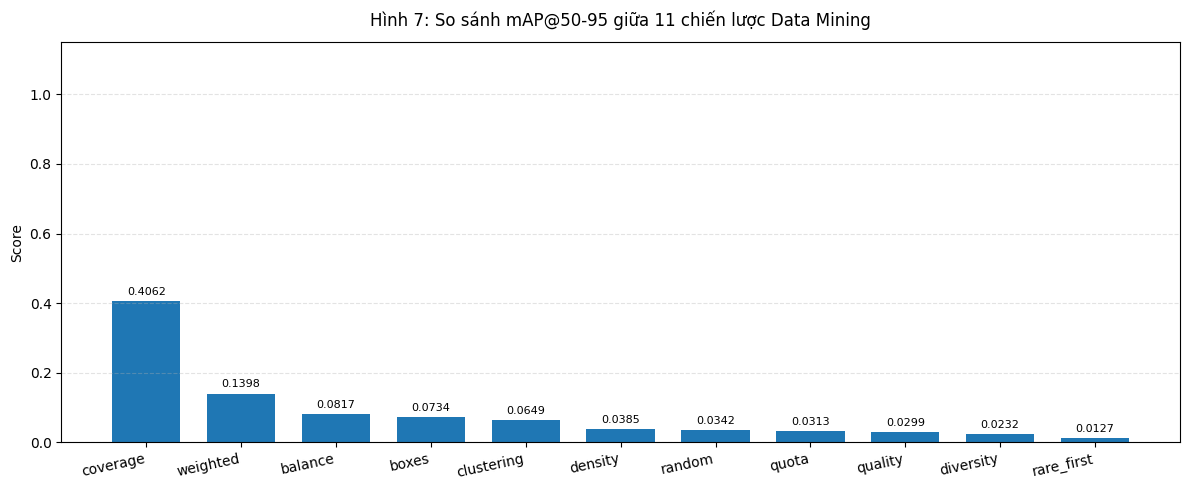

In [51]:
if leaderboard_rows:
    graphics.bars(
        leaderboard_rows,
        metrics=("mAP50-95",),
        error_bars=False,
        figsize=(12, 5),
        title="So sánh mAP@50-95 giữa 11 chiến lược Data Mining",
        save_path=REPORT_DIR / "fig_07_map50_95_comparison.png",
        dpi=300,
    )

In [1]:
if leaderboard_rows:
    graphics.bars(
        leaderboard_rows,
        metrics=("precision", "recall", "f1", "mAP50", "mAP50-95"),
        error_bars=False,
        show_values=False,
        figsize=(14, 5.2),
        title="So sánh đa chỉ số (P / R / F1 / mAP@50 / mAP@50-95)",
        save_path=REPORT_DIR / "fig_08_multi_metric_comparison.png",
        dpi=300,
    )
    multi_metric_rows = [
        {
            "rank": r["rank"],
            "strategy": r["strategy"],
            "P": round(float(r["precision"]), 4),
            "R": round(float(r["recall"]), 4),
            "F1": round(float(r["f1"]), 4),
            "mAP50": round(float(r["mAP50"]), 4),
            "mAP50-95": round(float(r["mAP50-95"]), 4),
        }
        for r in leaderboard_rows
    ]
    files.save(REPORT_DIR / "table_multi_metric_comparison.csv", multi_metric_rows, overwrite=True, verbose=False)

NameError: name 'leaderboard_rows' is not defined

In [ ]:
utils.tabulate(
    multi_metric_rows,
    title="So sánh chi tiết đa chỉ số hiệu năng — 11 chiến lược Data Mining",
)

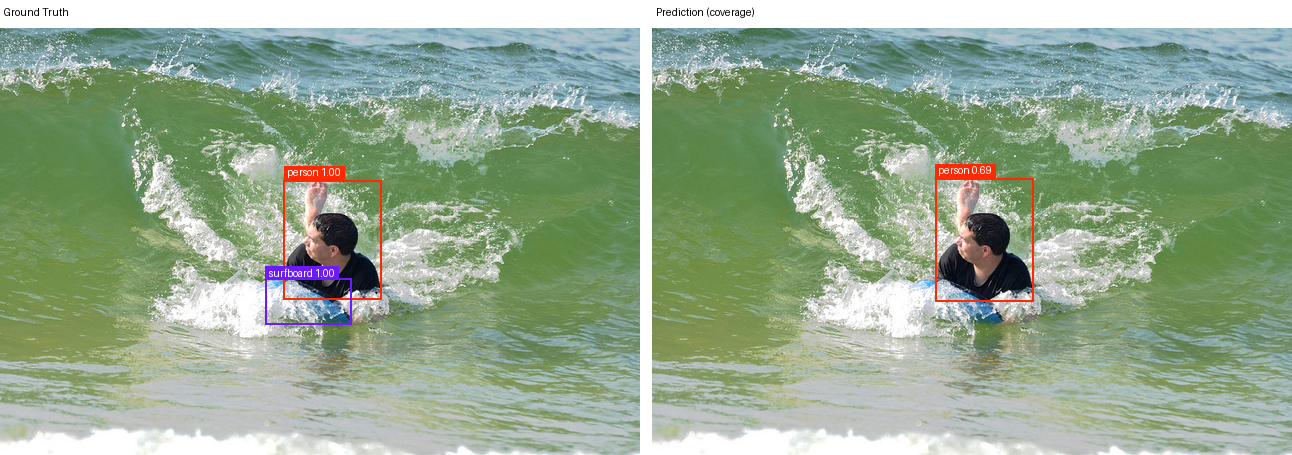

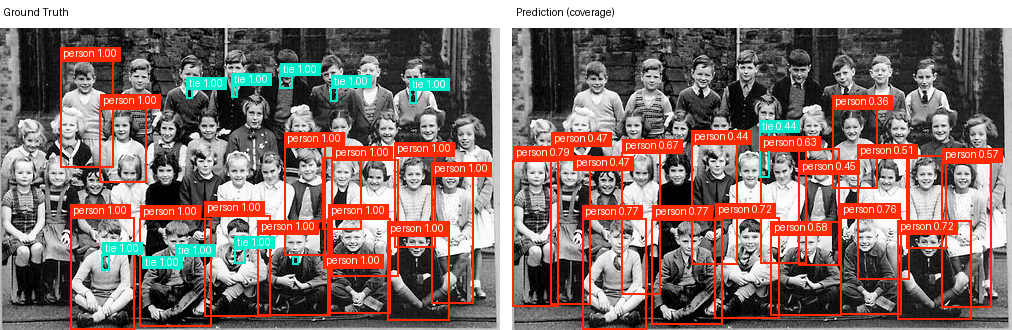

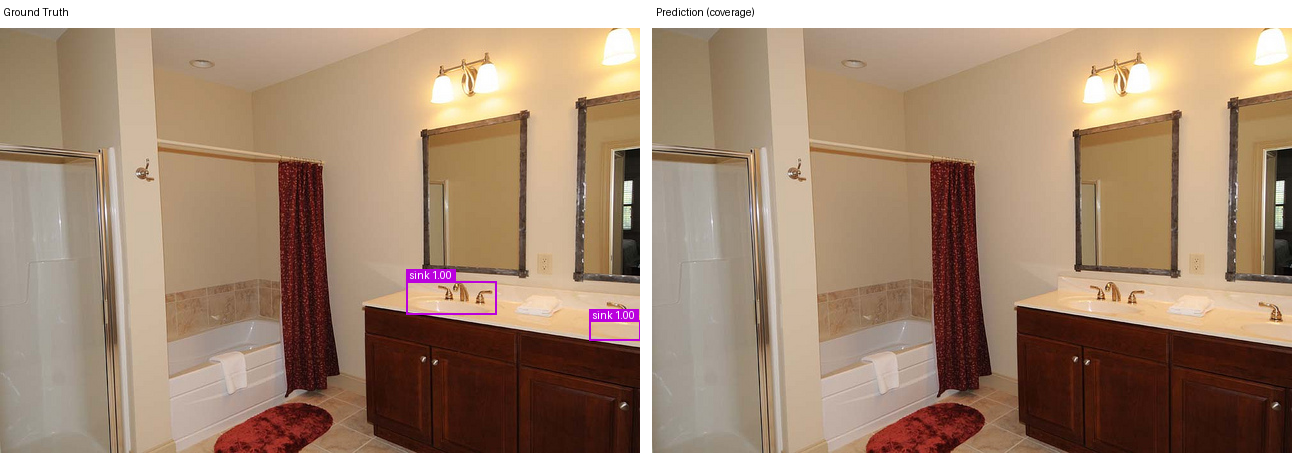

In [53]:
if leaderboard_rows:
    best_det = models.load(best_checkpoints[best_strategy])
    sample_dets = val_dets[:min(3, len(val_dets))].copy()
    sample_preds = sample_dets.copy()
    sample_preds.repredict(best_det, threshold=0.35, verbose=False)

    for idx in range(len(sample_dets)):
        preview = graphics.compare(
            sample_dets[idx],
            sample_preds[idx],
            titles=("Ground Truth", f"Prediction ({best_strategy})"),
            mode="save",
            output_path=REPORT_DIR / f"fig_09_qualitative_sample_{idx + 1}.png",
            overwrite=True,
        )
        graphics.show(preview, title=f"Ground Truth vs {best_strategy}")
    del best_det
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 9. Kiểm chứng độ ổn định 3 Seeds (`random` + Top-3 chiến lược tốt nhất)

In [54]:
multi_seed_runs = {}

if RUN_TRAINING and RUN_MULTI_SEED and leaderboard_rows:
    top_strategies = []
    for s in [r["strategy"] for r in leaderboard_rows[:3]] + ["random"]:
        if s not in top_strategies:
            top_strategies.append(s)

    for strategy in top_strategies:
        multi_seed_runs[strategy] = list(run_dirs[strategy])  # tái sử dụng seed 42 đã chạy
        for s_val in MULTI_SEEDS:
            if s_val == SEED:
                continue
            print(f"\n{'=' * 18} MULTI-SEED: {strategy} (seed={s_val}) {'=' * 18}")
            detector = models.load(MODEL_NAME)
            run_name = f"yolo11n_{strategy}_seed{s_val}"
            detector.model.train(
                data=dataset_yamls[strategy],
                project=str(RUNS_DIR),
                name=run_name,
                epochs=EPOCHS,
                imgsz=IMGSZ,
                batch=BATCH,
                workers=WORKERS,
                device=DEVICE,
                seed=s_val,
                deterministic=True,
                patience=EPOCHS,
                exist_ok=True,
            )
            run_dir = RUNS_DIR / run_name
            multi_seed_runs[strategy].append(str(run_dir))
            ckpt_src = run_dir / "weights" / "best.pt" if files.is_file(run_dir / "weights" / "best.pt") else run_dir / "weights" / "last.pt"
            files.copy(ckpt_src, CHECKPOINT_DIR / f"{strategy}_seed{s_val}_best.pt", overwrite=True)
            del detector
            if torch.cuda.is_available():
                torch.cuda.empty_cache()


================== MULTI-SEED: coverage (seed=100) ==================
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/coco_mining_project/artifacts/datasets/coverage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, mo

In [55]:
multi_agg = None
if multi_seed_runs:
    pair = (best_strategy, "random") if best_strategy != "random" else None
    multi_agg = reports.aggregate_runs(multi_seed_runs, format="yolo", best="auto", compare_pair=pair)
    files.save(REPORT_DIR / "table_multi_seed_summary.csv", multi_agg["table"], overwrite=True, verbose=False)
    files.save(LOG_DIR / "07a_multi_seed_delta.json", multi_agg["delta"], overwrite=True, verbose=False)
    utils.tabulate(multi_agg["table"], title="Kiểm chứng ổn định 3 Seeds (Mean ± Std — random + Top-3)")

Bảng 14a: Kiểm chứng ổn định 3 Seeds (Mean ± Std — random + Top-3)                                                                                  
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   strategy     seeds     precision_mean     precision_std     recall_mean     recall_std     f1_mean     f1_std     mAP50_mean     mAP50_std     mAP50-95_mean     mAP50-95_std     time_mean_s     time_std_s     best_epoch_mean   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage         3             0.6917            0.0083          0.4664          0.001      0.5571      0.002         0.5406        0.0012             0.406           0.0002            7.85           0.33                 1.3   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted         3             0.3901            0.0124          0.1654          0.005      0.2321     0.0027         0.1886        0.0021            0.1424           0.0014            8.99            0.4                 2.0   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   balance          3             0.3349            0.0064          0.0943            0.0      0.1472     0.0006         0.1121        0.0004            0.0816           0.0002            8.53           0.34                 1.0   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random           3             0.4099            0.0002          0.0374         0.0004      0.0686     0.0007         0.0515        0.0006            0.0348              0.0           10.05           2.89                 1.3   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [56]:
if multi_agg:
    files.save(REPORT_DIR / "table_multi_seed_per_seed.csv", multi_agg["per_seed"], overwrite=True, verbose=False)
    utils.tabulate(multi_agg["per_seed"], title="Kết quả chi tiết từng Seed (Phụ lục)")

Bảng 14b: Kết quả chi tiết từng Seed (Phụ lục)                                
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   strategy     seed     best_epoch     time_s     precision     recall         f1      mAP50     mAP50-95   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage       42              1       8.27        0.6835     0.4676     0.5553     0.5399       0.4063   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage      100              1       7.46        0.6885     0.4665     0.5562     0.5396       0.4057   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage     2024              2       7.83        0.7031     0.4652     0.5599     0.5423       0.4061   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted       42              2       8.59        0.3912     0.1645     0.2316     0.1857       0.1411   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted      100              2       8.85        0.4046     0.1597      0.229     0.1891       0.1418   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted     2024              2       9.53        0.3743     0.1719     0.2356     0.1908       0.1443   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   balance        42              1       8.39        0.3259     0.0943     0.1463     0.1122       0.0816   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   balance       100              1        8.2        0.3388     0.0944     0.1476     0.1116       0.0814   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   balance      2024              1        9.0        0.3401     0.0943     0.1476     0.1126       0.0819   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random         42              2      14.14        0.4097     0.0379     0.0694     0.0507       0.0348   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random        100              1       8.07        0.4098     0.0375     0.0687      0.052       0.0348   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random       2024              1       7.94        0.4101     0.0369     0.0677      0.052       0.0348   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────

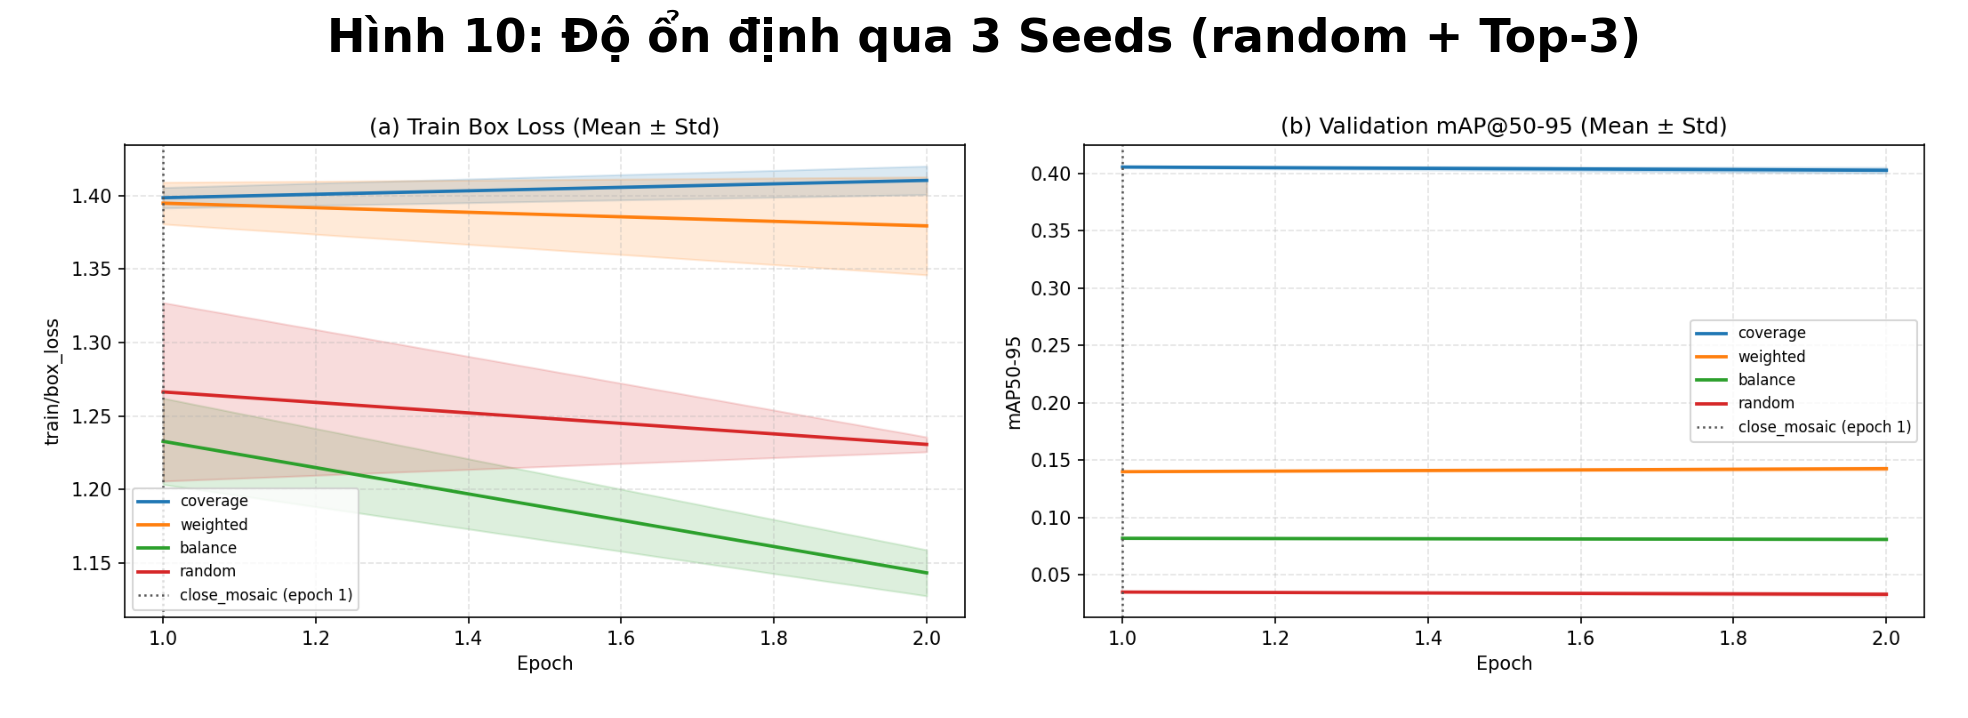

In [57]:
if multi_agg:
    # Hình 10a: 3 đường Training Loss (Mean ± Std)
    fig_ms_box = graphics.curves(multi_agg, metric="box_loss", split="train", band=True, show=False, return_figure=True)
    fig_ms_cls = graphics.curves(multi_agg, metric="cls_loss", split="train", band=True, show=False, return_figure=True)
    fig_ms_dfl = graphics.curves(multi_agg, metric="dfl_loss", split="train", band=True, show=False, return_figure=True)
    ms_loss_cells = graphics.compose([
        graphics.cell(fig_ms_box, title="(a) Train Box Loss (Mean ± Std)"),
        graphics.cell(fig_ms_cls, title="(b) Train Cls Loss (Mean ± Std)"),
        graphics.cell(fig_ms_dfl, title="(c) Train DFL Loss (Mean ± Std)"),
    ])
    graphics.grid(
        ms_loss_cells,
        rows=1,
        cols=3,
        title="Độ ổn định Training Loss qua 3 Seeds (random + Top-3)",
        save_path=REPORT_DIR / "fig_10a_multi_seed_loss_curves.png",
        dpi=300,
    )

In [ ]:
if multi_agg:
    fig_ms_m50 = graphics.curves(multi_agg, metric="mAP50", band=True, show=False, return_figure=True)
    fig_ms_m95 = graphics.curves(multi_agg, metric="mAP50-95", band=True, show=False, return_figure=True)
    ms_map_cells = graphics.compose([
        graphics.cell(fig_ms_m50, title="(a) Validation mAP@50 (Mean ± Std)"),
        graphics.cell(fig_ms_m95, title="(b) Validation mAP@50-95 (Mean ± Std)"),
    ])
    graphics.grid(
        ms_map_cells,
        rows=1,
        cols=2,
        title="Độ ổn định Validation mAP qua 3 Seeds (random + Top-3)",
        save_path=REPORT_DIR / "fig_10b_multi_seed_map_curves.png",
        dpi=300,
    )

In [ ]:
if multi_agg:
    fig_ms_p = graphics.curves(multi_agg, metric="precision", band=True, show=False, return_figure=True)
    fig_ms_r = graphics.curves(multi_agg, metric="recall", band=True, show=False, return_figure=True)
    fig_ms_f1 = graphics.curves(multi_agg, metric="f1", band=True, show=False, return_figure=True)
    ms_prf_cells = graphics.compose([
        graphics.cell(fig_ms_p, title="(a) Validation Precision (Mean ± Std)"),
        graphics.cell(fig_ms_r, title="(b) Validation Recall (Mean ± Std)"),
        graphics.cell(fig_ms_f1, title="(c) Validation F1-Score (Mean ± Std)"),
    ])
    graphics.grid(
        ms_prf_cells,
        rows=1,
        cols=3,
        title="Độ ổn định Precision, Recall & F1 qua 3 Seeds (random + Top-3)",
        save_path=REPORT_DIR / "fig_10c_multi_seed_prf1_curves.png",
        dpi=300,
    )

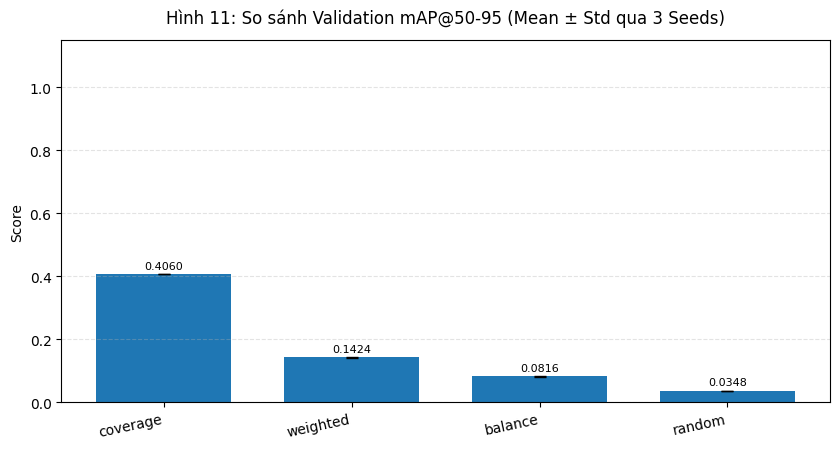

In [58]:
if multi_agg:
    graphics.bars(
        multi_agg["table"],
        metrics=("mAP50-95",),
        error_bars=True,
        title="So sánh Validation mAP@50-95 (Mean ± Std qua 3 Seeds)",
        save_path=REPORT_DIR / "fig_11_multi_seed_bars.png",
        dpi=300,
    )

## 10. Khảo sát hiệu quả dữ liệu theo ngân sách (`BUDGET_GRID`: 250 / 550 / 1000 ảnh)

In [59]:
scaling_rows = []

if RUN_TRAINING and RUN_BUDGET_SCALING and leaderboard_rows:
    scale_strategies = ["random"] if best_strategy == "random" else ["random", best_strategy]
    for budget_k in BUDGET_GRID:
        for strategy in scale_strategies:
            if budget_k == TRAIN_BUDGET:
                base_rec = next(r for r in training_records if r["strategy"] == strategy)
                scaling_rows.append({"label": f"{strategy}@{budget_k}", "budget": budget_k, **base_rec})
                continue

            if strategy == "random":
                sub_k = mining.select(clean_pool, method="random", limit=budget_k, seed=SEED)
            elif strategy == "rare_first":
                sub_k = mining.select(clean_pool, method="rare_first", limit=budget_k)
            elif strategy == "density":
                sub_k = mining.select(clean_pool, method="weighted", scores=density_scores, limit=budget_k)
            elif strategy == "weighted":
                sub_k = mining.select(clean_pool, method="weighted", scores=weighted_scores, limit=budget_k)
            elif strategy == "quality":
                sub_k = mining.select(clean_pool, method="quality", threshold=0.0, limit=budget_k)
            elif strategy == "boxes":
                sub_k = mining.select(clean_pool, method="boxes", min_boxes=2, min_area_ratio=0.002, limit=budget_k)
            elif strategy == "coverage":
                sub_k = mining.select(clean_pool, method="coverage", limit=budget_k)
            elif strategy == "quota":
                sub_k = mining.select(clean_pool, method="quota", per_class=max(1, budget_k // 55), limit=budget_k)
            elif strategy == "diversity":
                cl_k = mining.cluster(clean_pool, clusters=min(budget_k, len(clean_pool)), seed=SEED)
                sub_k = mining.select(clean_pool, method="diversity", cluster_result=cl_k, per_cluster=1, limit=budget_k, seed=SEED)
            elif strategy == "clustering":
                q_k = max(1, (budget_k + N_CLUSTERS - 1) // N_CLUSTERS)
                sub_k = mining.select(clean_pool, method="diversity", cluster_result=cluster_grp, per_cluster=q_k, limit=budget_k, seed=SEED)
            else:
                sub_k = mining.select(balanced_pool, method="random", limit=budget_k, seed=SEED)

            strat_dir = DATASET_DIR / f"scale_{strategy}_{budget_k}"
            sub_k.export(str(strat_dir), format="yolo", image=True, overwrite=True)
            yaml_path = strat_dir / "data.yaml"
            data_cfg = config.load(yaml_path, verbose=False)
            data_cfg = config.set(data_cfg, "path", str(strat_dir))
            data_cfg = config.set(data_cfg, "train", "images")
            data_cfg = config.set(data_cfg, "val", str(VAL_YOLO_DIR / "images"))
            files.save(yaml_path, data_cfg.to_dict(), overwrite=True, verbose=False)

            detector = models.load(MODEL_NAME)
            run_name = f"yolo11n_scale_{strategy}_{budget_k}"
            detector.model.train(
                data=str(yaml_path),
                project=str(RUNS_DIR),
                name=run_name,
                epochs=EPOCHS,
                imgsz=IMGSZ,
                batch=BATCH,
                workers=WORKERS,
                device=DEVICE,
                seed=SEED,
                deterministic=True,
                patience=EPOCHS,
                exist_ok=True,
            )
            run_dir = RUNS_DIR / run_name
            ckpt_src = run_dir / "weights" / "best.pt" if files.is_file(run_dir / "weights" / "best.pt") else run_dir / "weights" / "last.pt"
            ckpt_dst = CHECKPOINT_DIR / f"scale_{strategy}_{budget_k}_best.pt"
            files.copy(ckpt_src, ckpt_dst, overwrite=True)

            eval_det = models.load(ckpt_dst)
            y_val = eval_det.model.val(
                data=str(yaml_path),
                split="val",
                imgsz=IMGSZ,
                batch=BATCH,
                device=DEVICE,
                verbose=False,
            )
            mp = float(y_val.box.mp)
            mr = float(y_val.box.mr)
            f1 = float(metrics.f1_score(mp, mr))

            scaling_rows.append({
                "label": f"{strategy}@{budget_k}",
                "budget": budget_k,
                "strategy": strategy,
                "train_images": len(sub_k),
                "precision": round(mp, 4),
                "recall": round(mr, 4),
                "f1": round(f1, 4),
                "mAP50": round(float(y_val.box.map50), 4),
                "mAP75": round(float(y_val.box.map75), 4),
                "mAP50-95": round(float(y_val.box.map), 4),
            })
            del detector, eval_det
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/coco_mining_project/artifacts/datasets/scale_random_50/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_scale_ra

In [60]:
if scaling_rows:
    files.save(REPORT_DIR / "table_budget_scaling.csv", scaling_rows, overwrite=True, verbose=False)
    utils.tabulate(scaling_rows, title="Hiệu quả sử dụng dữ liệu theo ngân sách (Budget Scaling)")

Bảng 15: Hiệu quả sử dụng dữ liệu theo ngân sách (Budget Scaling)                                 
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   label            budget     strategy     train_images     precision     recall         f1      mAP50      mAP75     mAP50-95   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random@50            50     random                 50        0.5684     0.0501     0.0921     0.0669     0.0424       0.0445   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage@50          50     coverage               50        0.6795     0.4587     0.5477     0.5341      0.439       0.4045   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random@100          100     random                100        0.4093     0.0382     0.0699     0.0511     0.0347       0.0342   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage@100        100     coverage              100        0.6761     0.4597     0.5473      0.533     0.4421       0.4062   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random@150          150     random                150        0.4259     0.1663     0.2392     0.1921     0.1677       0.1453   
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage@150        150     coverage              150        0.6863     0.4582     0.5496     0.5341       0.44       0.4042   
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

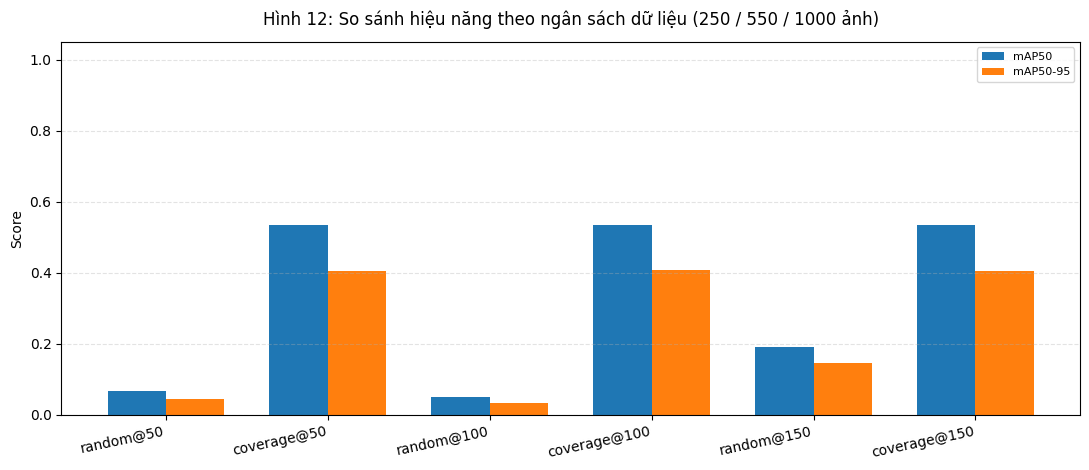

In [61]:
if scaling_rows:
    bar_rows = [{"strategy": r["label"], "mAP50": r["mAP50"], "mAP50-95": r["mAP50-95"]} for r in scaling_rows]
    graphics.bars(
        bar_rows,
        metrics=("mAP50", "mAP50-95"),
        error_bars=False,
        show_values=False,
        figsize=(11, 4.8),
        title="So sánh hiệu năng theo ngân sách dữ liệu (250 / 550 / 1000 ảnh)",
        save_path=REPORT_DIR / "fig_12_budget_scaling.png",
        dpi=300,
    )

## 11. Kiểm toán tổng hợp & Đóng gói ZIP bàn giao (`klygo.files` + `klygo.archive`)

In [62]:
mining_by_strat = {r["strategy"]: r for r in mining_rows}
lb_by_strat = {r["strategy"]: r for r in leaderboard_rows} if leaderboard_rows else {}

final_audit_rows = [
    {
        "strategy": s,
        "images": mining_by_strat[s]["images"],
        "boxes": mining_by_strat[s]["boxes"],
        "class_coverage": mining_by_strat[s]["class_coverage"],
        "imbalance_ratio": mining_by_strat[s]["imbalance_ratio"],
        **({
            "rank": lb_by_strat[s]["rank"],
            "precision": lb_by_strat[s]["precision"],
            "recall": lb_by_strat[s]["recall"],
            "f1": lb_by_strat[s]["f1"],
            "mAP50": lb_by_strat[s]["mAP50"],
            "mAP50-95": lb_by_strat[s]["mAP50-95"],
            "delta_pct": lb_by_strat[s]["delta_pct"],
        } if s in lb_by_strat else {}),
    }
    for s in selections
]
files.save(REPORT_DIR / "table_final_audit.csv", final_audit_rows, overwrite=True, verbose=False)
utils.tabulate(final_audit_rows, title="Bảng tổng hợp kiểm toán toàn bộ 11 chiến lược")

Bảng 13: Bảng tổng hợp kiểm toán toàn bộ 11 chiến lược                                                     
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   strategy       images     boxes     class_coverage     imbalance_ratio     rank     precision     recall         f1      mAP50     mAP50-95     delta_pct   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   random            100       834                 63                52.0        7        0.4093     0.0382     0.0699     0.0511       0.0342           0.0   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   rare_first        100       535                 58                17.0       11        0.5171     0.0143     0.0279     0.0195       0.0127        -62.87   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   density           100      1893                 70                76.0        6        0.4169     0.0384     0.0703     0.0572       0.0385         12.57   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   weighted          100      1502                 76                52.0        2         0.376      0.165     0.2293     0.1846       0.1398        308.77   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   quality           100       701                 70                43.0        9        0.4055     0.0357     0.0657     0.0451       0.0299        -12.57   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   boxes             100       773                 70                55.0        4        0.3319     0.1006     0.1543     0.1002       0.0734        114.62   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   coverage          100      1697                 79                71.0        1        0.6761     0.4597     0.5473      0.533       0.4062       1087.72   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   quota             100      1309                 72                66.0        8        0.3007     0.0352      0.063     0.0455       0.0313         -8.48   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   diversity         100       808                 72                54.0       10        0.3179     0.0254     0.0471     0.0353       0.0232        -32.16   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   clustering        100       719                 69                53.0        5        0.3487     0.0724     0.1199     0.0885       0.0649         89.77   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   balance           100       718                 74                49.0        3        0.3411     0.0944     0.1479      0.112       0.0817        138.89   
 ───────────────────────────────────────────────────

In [63]:
files.save(ROOT / "README.md", f"# COCO Ground-Truth Data Mining + YOLO11n (Klygo)\n- Pool: {POOL_LIMIT} | Val: {VAL_LIMIT} | Budget: {TRAIN_BUDGET} | Strategies: 11 | Model: {MODEL_NAME} | Epochs: {EPOCHS}\n", overwrite=True, verbose=False)
files.save(ROOT / "requirements.txt", "klygo[ultralytics]\nnumpy\ntorch\n", overwrite=True, verbose=False)

ZIP_PATH = files.path("/content/COCO_GroundTruth_DataMining_YOLO11n_Klygo.zip")
PACKAGE_ROOT = ROOT / "package"
files.remove(ZIP_PATH, missing_ok=True)
files.remove(PACKAGE_ROOT, missing_ok=True)
files.mkdir(PACKAGE_ROOT)

# Chỉ đóng gói logs, reports, checkpoints và runs (kèm weights); KHÔNG đóng gói dataset ảnh để ZIP gọn nhẹ
for sub in ["logs", "reports", "checkpoints", "runs"]:
    src = ARTIFACTS / sub
    if files.is_dir(src):
        files.copy(src, PACKAGE_ROOT / "artifacts" / sub, overwrite=True)
files.copy(ROOT / "README.md", PACKAGE_ROOT / "README.md", overwrite=True)
files.copy(ROOT / "requirements.txt", PACKAGE_ROOT / "requirements.txt", overwrite=True)

In [64]:
inventory = [
    {"path": str(p.relative_to(PACKAGE_ROOT)), "size": files.size(p), "sha256": files.hash(p, algorithm="sha256")}
    for p in files.find(PACKAGE_ROOT, recursive=True)
]
files.save(PACKAGE_ROOT / "artifacts" / "logs" / "08_package_inventory.json", inventory, overwrite=True, verbose=False)
archive.compress(PACKAGE_ROOT, ZIP_PATH, overwrite=True, verbose=True)


COCO_GroundTruth_DataMining_YOLO11n_Klygo.zip: compressing:   0%|          | 0.00/552 [00:00<?, ?file/s]

In [65]:
zip_info = {
    "zip_path": str(ZIP_PATH),
    "size": utils.human_size(files.size(ZIP_PATH)),
    "entries": len(archive.list_files(ZIP_PATH)),
    "sha256": files.hash(ZIP_PATH, algorithm="sha256"),
}
utils.tabulate(zip_info, orient="horizontal", title="Thông tin gói bàn giao ZIP")

try:
    from google.colab import files as colab_files
    colab_files.download(str(ZIP_PATH))
except ImportError:
    print("ZIP saved locally at:", ZIP_PATH)


Bảng 16: Thông tin gói bàn giao ZIP                                                            
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   zip_path                                                   size          entries     sha256                                                             
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   /content/COCO_GroundTruth_DataMining_YOLO11n_Klygo.zip     499.36 MB         552     af8cc8097968daaee3803f8a080b836c038f44155ef6ad5277d5f3f61843348f   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Tự động ngắt runtime Colab L4 sau khi chạy xong

In [66]:
# Chờ 15 giây để trình duyệt hoàn tất tải ZIP rồi tự động ngắt GPU runtime tránh tốn Compute Units
import time

AUTO_SHUTDOWN = True
if AUTO_SHUTDOWN:
    try:
        from google.colab import runtime
        print("All experiments finished! Waiting 15s before shutting down Colab runtime...")
        time.sleep(15)
        runtime.unassign()
    except ImportError:
        print("Not running in Google Colab — skipping runtime.unassign().")

All experiments finished! Waiting 15s before shutting down Colab runtime...
